# **STELLAR OBJECTS CLASSIFICATION — FINAL PROJECT ML**

**Paper:** *Astronomical Object Classification Based On SDSS Spectral Data*  
**Authors:**  Group 6

| Nama              | NRP        |
|-------------------|------------|
| Nabila Shafa Rahayu      | 5025241150 |
| Shabrina Amalia Safaana      | 5025241157 |
| Dilbina Windi Azahra       | 5025241180 |
| Nasyita Larasati Ertyananda      | 5025241201 |
| Rahma Sakinah       | 5025241222 |

**Kelas:** Machine Learning (D)

-----------------------------------
Notebook ini mengklasifikasikan objek langit, yaitu **galaxy**, **star**, dan **QSO (Quasi-Stellar Object)** menggunakan dataset **SDSS DR17 (Sloan Digital Sky Survey Data Release 17)** yang terdiri dari 100.000 data dengan 18 kolom. Dengan 4 model Machine Learning dan 1 model Deep Learning diterapkan dan dibandingkan performanya across 5 skenario fitur yang berbeda.

## **1. Import Library**

Cell ini berfungsi untuk mengimpor seluruh library yang dibutuhkan dalam klasifikasi. 

Library yang digunakan jika dikelompokkan berdasarkan fungsinya:

**Library Umum**
- `numpy` dan `pandas`digunakan untuk manipulasi data numerik dan tabular.
- `matplotlib` dan `seaborn` digunakan untuk visualisasi data seperti histogram, pie chart, dan confusion matrix.
- `math` digunakan untuk operasi matematis dasar, seperti menghitung jumlah baris pada subplot.
- `warnings.filterwarnings('ignore')` digunakan untuk menyembunyikan pesan peringatan yang tidak krusial agar output notebook lebih bersih.

**Preprocessing**
- `StandardScaler` digunakan untuk normalisasi fitur agar memiliki mean 0 dan standar deviasi 1.
- `train_test_split` digunakan untuk membagi dataset menjadi subset train, validation, dan test.
- `cross_val_score` dan `StratifiedKFold` diimpor sebagai utilitas evaluasi tambahan yang mempertahankan proporsi kelas pada setiap fold.

**Penanganan Class Imbalance**
`SMOTE` (Synthetic Minority Over-sampling Technique) dari library `imbalanced-learn` digunakan untuk membangkitkan sampel sintetis pada kelas minoritas, sehingga distribusi kelas pada data training menjadi seimbang.

**Model Machine Learning**
- Tiga model baseline sesuai paper: `RandomForestClassifier`, `KNeighborsClassifier`, dan `MLPClassifier`.
- Tiga model tambahan: `XGBClassifier`, `LGBMClassifier`, serta Custom Dense Neural Network menggunakan `TensorFlow` dan `Keras`.

**Evaluasi**
`accuracy_score`, `classification_report`, `confusion_matrix`, `ConfusionMatrixDisplay`, `precision_score`, `recall_score`, dan `f1_score` digunakan untuk mengukur dan menampilkan performa model secara komprehensif.

**Reproducibility**
`RANDOM_STATE = 42` ditetapkan sebagai seed global. Nilai ini kemudian digunakan pada `np.random.seed()` dan `tf.random.set_seed()` untuk memastikan hasil eksperimen konsisten dan dapat direproduksi di setiap kali notebook dijalankan ulang.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import math
import warnings
warnings.filterwarnings('ignore')

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# SMOTE untuk penanganan class imbalance
from imblearn.over_sampling import SMOTE

# Models  4 Baseline (dari Paper 1)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Models  4 Tambahan
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
# Custom Dense Neural Network akan dibuat menggunakan TensorFlow/Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Evaluation
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print('Semua library berhasil di-import')
print(f'   numpy       : {np.__version__}')
print(f'   pandas      : {pd.__version__}')
print(f'   sklearn     : ', end='')
import sklearn; print(sklearn.__version__)
print(f'   tensorflow  : {tf.__version__}')
print(f'   RANDOM_STATE = {RANDOM_STATE}')


Semua library berhasil di-import
   numpy       : 2.2.6
   pandas      : 2.3.3
   sklearn     : 1.7.2
   tensorflow  : 2.21.0
   RANDOM_STATE = 42


## **2. Load Dataset**

Dataset yang digunakan adalah **SSDS DR17 (Sloan Digital Sky Survey Data Release 17)**, terdapat 100.000 data objek astronomi yang telah dilabeli menjadi tiga jenis objek, yaitu Star, Galaxy, dan QSO dengan 17 fitur.

Dataset ini tersedia secara publik dan diambil dari **HuggingFace** *https://huggingface.co/datasets/AethronPhantom/Astro* 

In [3]:
df = pd.read_csv('star_classification.csv')

print(f'Shape dataset: {df.shape}')
print(f'\nKolom dataset:')
print(df.columns.tolist())
print(f'\nDistribusi kelas:')
print(df['class'].value_counts())
df.head()

Shape dataset: (100000, 18)

Kolom dataset:
['obj_ID', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID', 'spec_obj_ID', 'class', 'redshift', 'plate', 'MJD', 'fiber_ID']

Distribusi kelas:
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


Terdapat persebaran kelas yang tidak merata dengan data dominan di **Galaxy** yaitu sebesar **59,4%**

## **3. EDA**

In [4]:
print('=== Info Dataset ===')
print(df.info())
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\n=== Statistik Deskriptif ===')
df.describe()

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: f

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


Kesimpulan:
- Tidak ada missing value dalam dataset ini
- Fitur yang kemungkinan dapat berguna untuk analisis hanya beberapa
- Atribut berjenis fotometri ada 5 kolom: u, g, r, i, dan z
- Atribut yang berhubungan dengan posisi objek ada 3 kolom: alpha, delta, dan redshift
- Skala tiap atribut sangat berbeda, sehingga perlu di normalisasi

### **3.1 Class Distribution (Pie Chart)**

Distribusi kelas:
  GALAXY    :  59445 (59.4%)
  STAR      :  21594 (21.6%)
  QSO       :  18961 (19.0%)


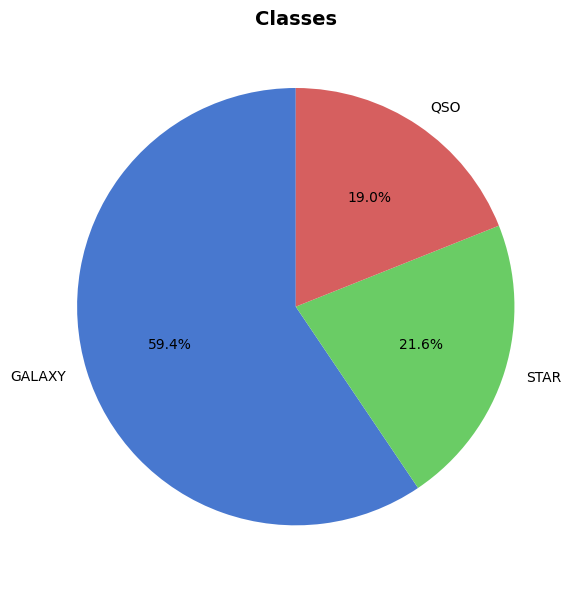

In [5]:
class_counts = df['class'].value_counts()
class_pct    = df['class'].value_counts(normalize=True) * 100

print('Distribusi kelas:')
for cls in class_counts.index:
    print(f'  {cls:10s}: {class_counts[cls]:6d} ({class_pct[cls]:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 6))
colors = ['#4878CF', '#6ACC65', '#D65F5F']
ax.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90
)
ax.set_title('Classes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Dapat dilihat persebaran kelas yang tidak merata

## **4. Feature Selection**

Berdasarkan rencana pengujian, dibuat **5 skenario variasi fitur** untuk perbandingan yang komprehensif:

| Skenario | Fitur | Jumlah |
|----------|-------|--------|
| **A. Baseline** | redshift, u, g, r, i, z | 6 |
| **B. Ekstensif** | redshift, u, g, r, i, z, alpha, delta | 8 |
| **C. Spasial** | alpha, delta | 2 |
| **D. Fotometri** | u, g, r, i, z | 5 |
| **E. Astrometri Kinematik** | redshift, alpha, delta | 3 |

**Insight:** Skenario ini akan menguji secara mendalam kontribusi tiap jenis fitur (fotometri, spasial, kinematik) terhadap klasifikasi objek.


In [5]:
BASELINE = ['redshift', 'u', 'g', 'r', 'i', 'z']
EKSTENSIF = ['redshift', 'u', 'g', 'r', 'i', 'z', 'alpha', 'delta']
SPASIAL = ['alpha', 'delta']
FOTOMETRI = ['u', 'g', 'r', 'i', 'z']
ASTROMETRI_KINEMATIK = ['redshift', 'alpha', 'delta']
TARGET = 'class'

scenarios = {
    'A_Baseline': BASELINE,
    'B_Ekstensif': EKSTENSIF,
    'C_Spasial': SPASIAL,
    'D_Fotometri': FOTOMETRI,
    'E_Astrometri_Kinematik': ASTROMETRI_KINEMATIK,
}

data_skenario = {}

for nama_skenario, FEATURES in scenarios.items():
    X = df[FEATURES].copy()
    y = df[TARGET].copy()

    data_skenario[nama_skenario] = {
        'FEATURES': FEATURES,
        'X': X,
        'y': y
    }

    print(f'\n=== {nama_skenario} ===')
    print(f'Fitur yang digunakan : {FEATURES}')
    print(f'Shape X              : {X.shape}')
    print(f'Shape y              : {y.shape}')
    print(f'Kelas                : {sorted(y.unique().tolist())}')



=== A_Baseline ===
Fitur yang digunakan : ['redshift', 'u', 'g', 'r', 'i', 'z']
Shape X              : (100000, 6)
Shape y              : (100000,)
Kelas                : ['GALAXY', 'QSO', 'STAR']

=== B_Ekstensif ===
Fitur yang digunakan : ['redshift', 'u', 'g', 'r', 'i', 'z', 'alpha', 'delta']
Shape X              : (100000, 8)
Shape y              : (100000,)
Kelas                : ['GALAXY', 'QSO', 'STAR']

=== C_Spasial ===
Fitur yang digunakan : ['alpha', 'delta']
Shape X              : (100000, 2)
Shape y              : (100000,)
Kelas                : ['GALAXY', 'QSO', 'STAR']

=== D_Fotometri ===
Fitur yang digunakan : ['u', 'g', 'r', 'i', 'z']
Shape X              : (100000, 5)
Shape y              : (100000,)
Kelas                : ['GALAXY', 'QSO', 'STAR']

=== E_Astrometri_Kinematik ===
Fitur yang digunakan : ['redshift', 'alpha', 'delta']
Shape X              : (100000, 3)
Shape y              : (100000,)
Kelas                : ['GALAXY', 'QSO', 'STAR']


## **5. Visualisasi Distribusi Fitur  — Sebelum Normalisasi**
Untuk melihat persebaran distribusi data

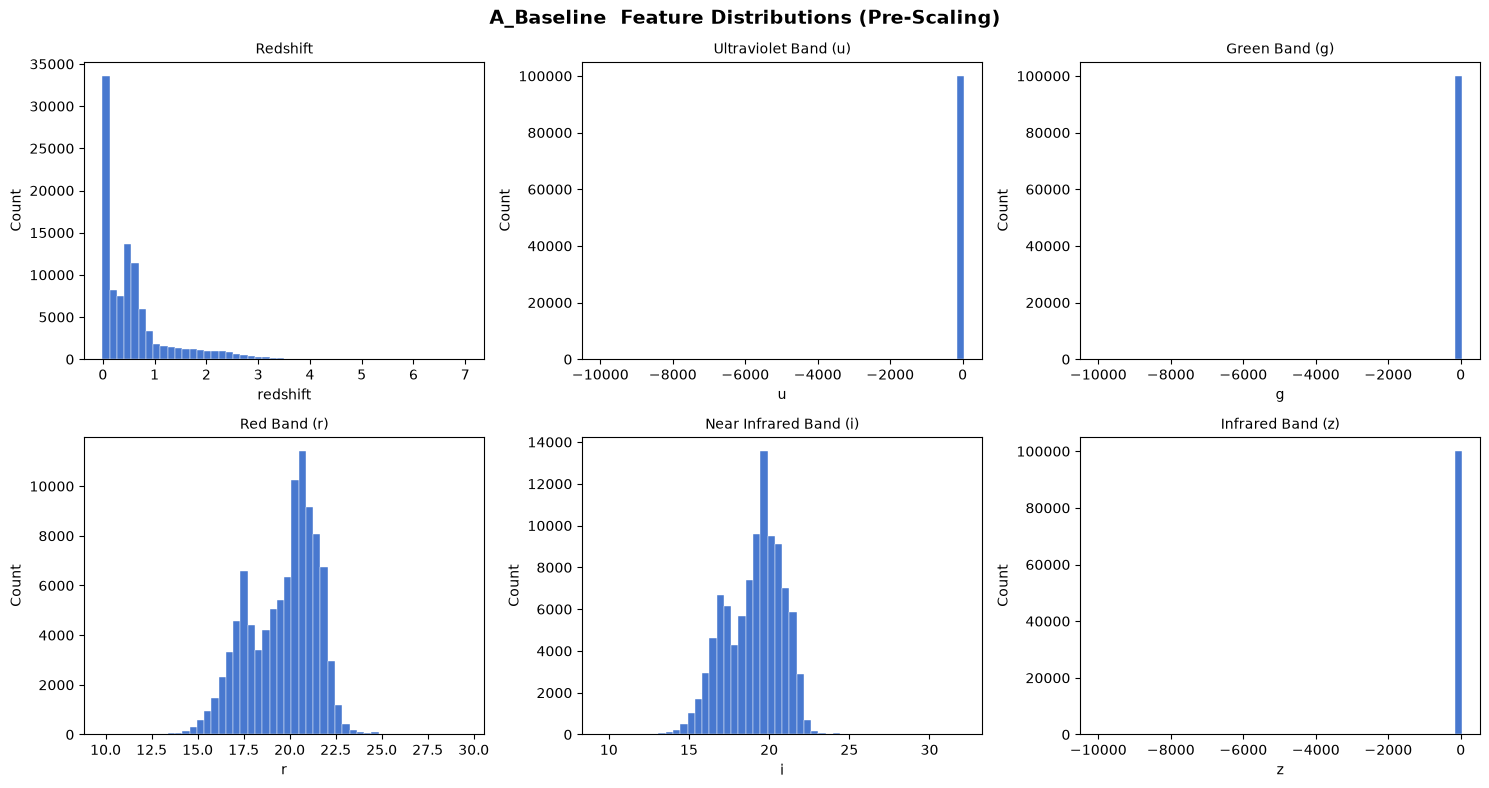

A_Baseline - Pre-Scaling Histograms


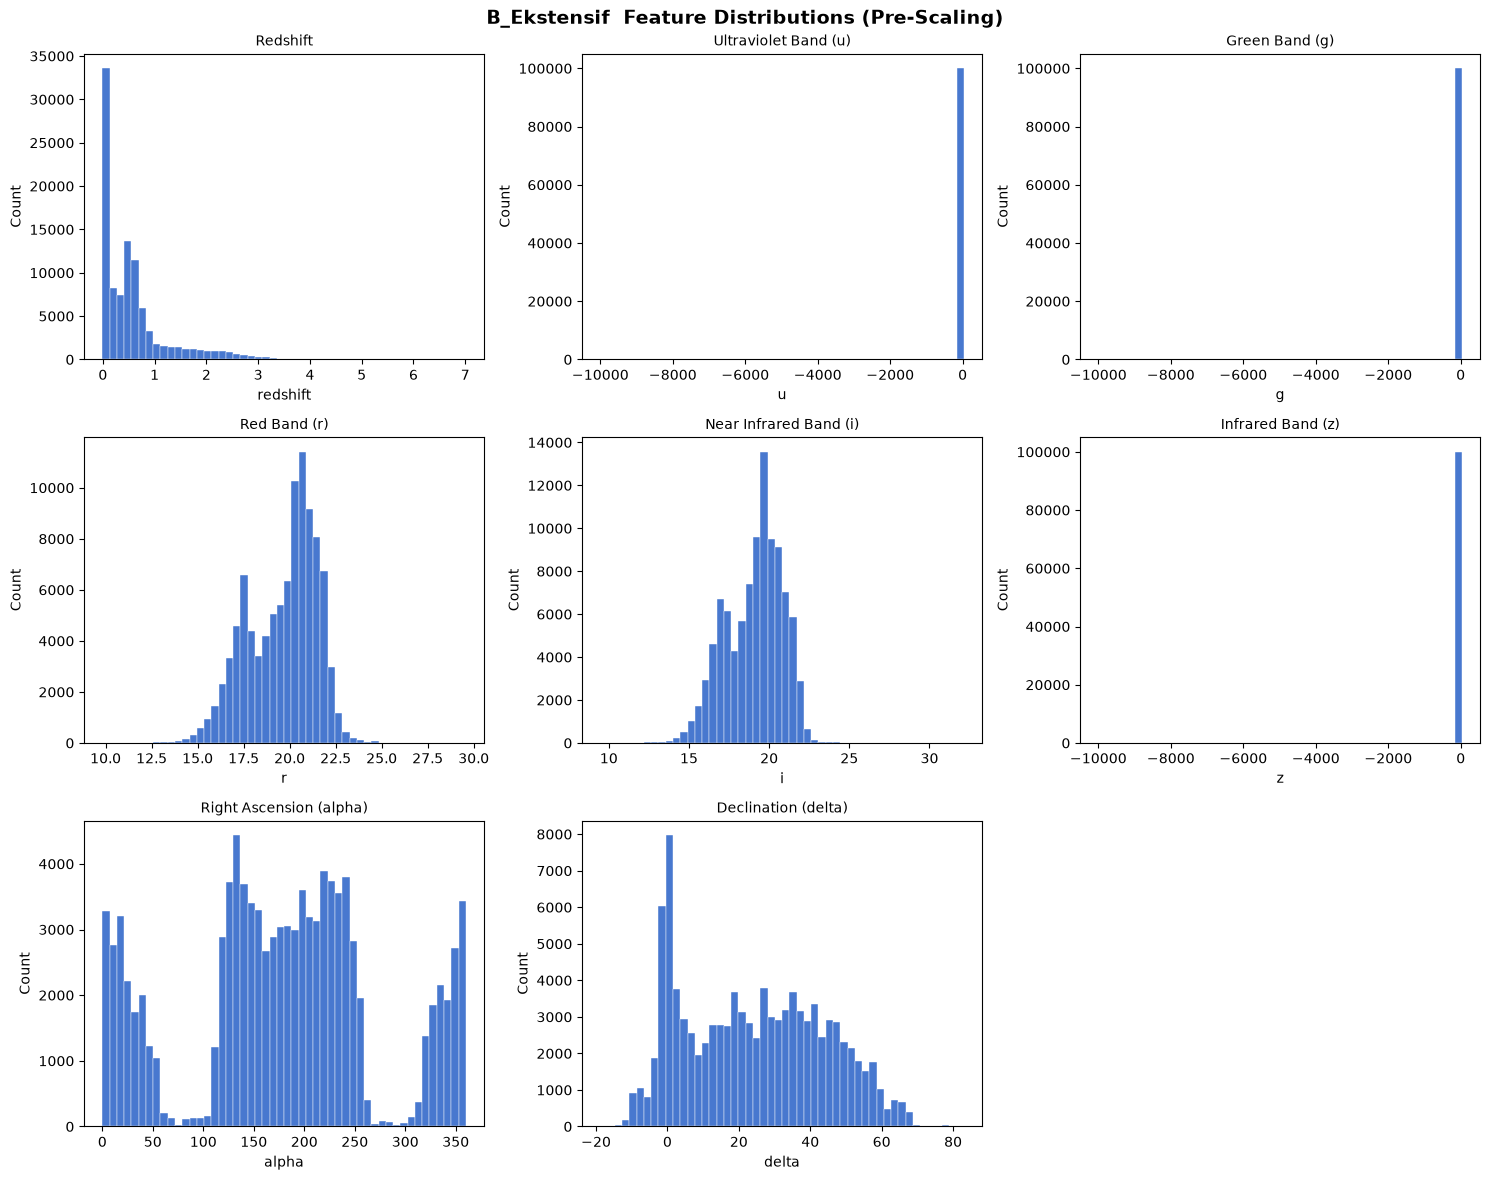

B_Ekstensif - Pre-Scaling Histograms


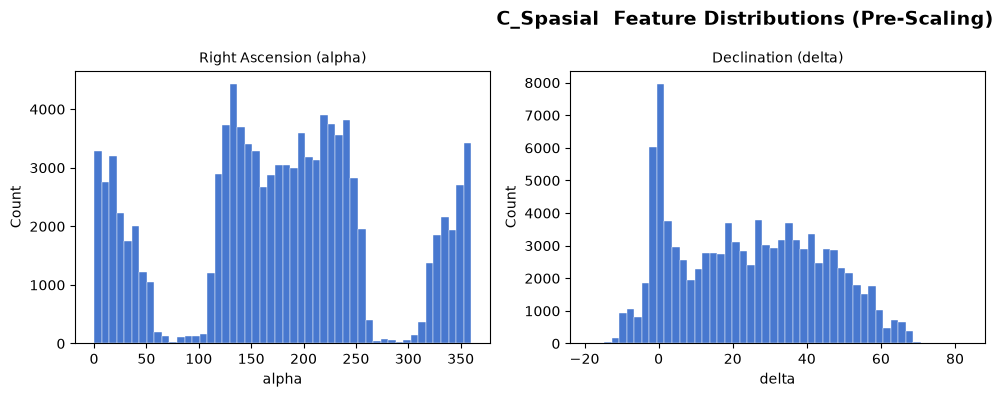

C_Spasial - Pre-Scaling Histograms


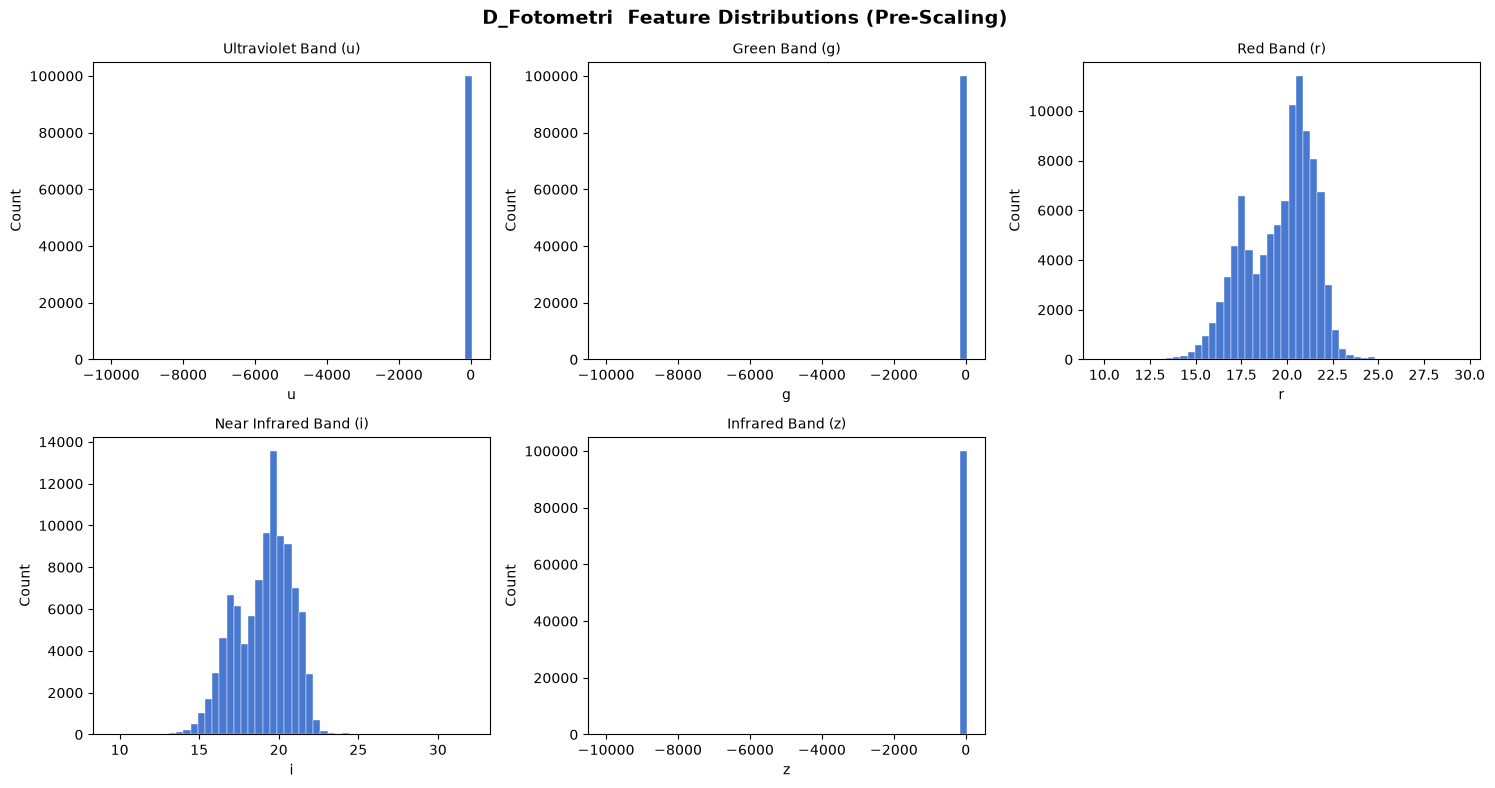

D_Fotometri - Pre-Scaling Histograms


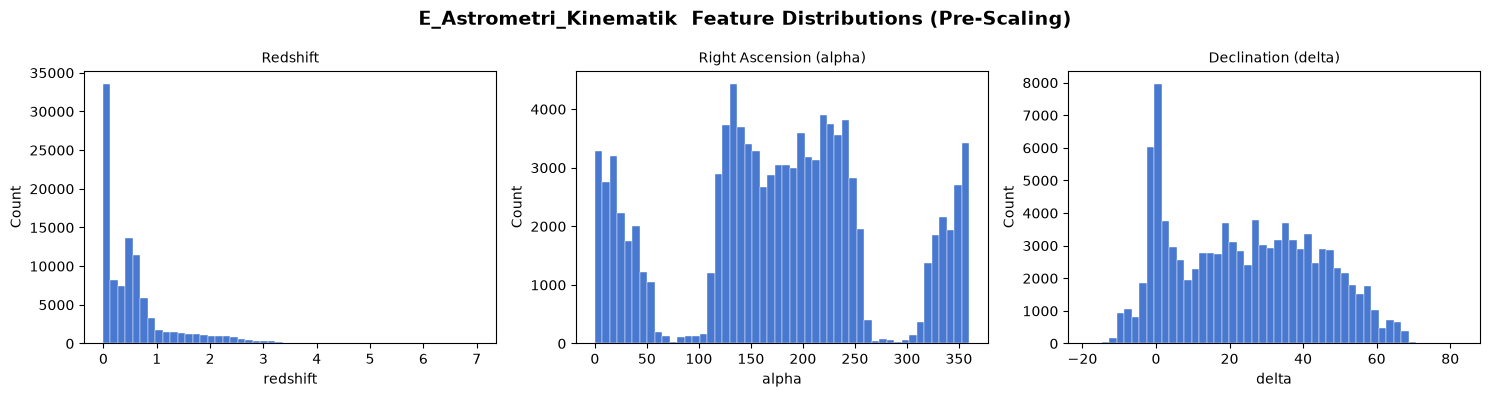

E_Astrometri_Kinematik - Pre-Scaling Histograms


In [6]:
feature_labels = {
    'alpha'    : 'Right Ascension (alpha)',
    'delta'    : 'Declination (delta)',
    'redshift' : 'Redshift',
    'u'        : 'Ultraviolet Band (u)',
    'g'        : 'Green Band (g)',
    'r'        : 'Red Band (r)',
    'i'        : 'Near Infrared Band (i)',
    'z'        : 'Infrared Band (z)'
}

for nama_skenario, data in data_skenario.items():

    X = data['X']
    features = data['FEATURES']

    n_features = len(features)
    n_cols = 3
    n_rows = math.ceil(n_features / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(5 * n_cols, 4 * n_rows)
    )

    if n_features > 1:
        axes = axes.flatten()
    else:
        axes = [axes]

    for idx, feat in enumerate(features):
        axes[idx].hist(
            X[feat], bins=50,
            color='#4878CF', edgecolor='white', linewidth=0.3
        )
        axes[idx].set_title(f'{feature_labels.get(feat, feat)}', fontsize=10)
        axes[idx].set_xlabel(feat)
        axes[idx].set_ylabel('Count')

    for idx in range(n_features, len(axes)):
        fig.delaxes(axes[idx])

    plt.suptitle(
        f'{nama_skenario}  Feature Distributions (Pre-Scaling)',
        fontsize=14, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()
    print(f'{nama_skenario} - Pre-Scaling Histograms')


**Insight:**
- Dapat dilihat untuk fitur redshift, distribusinya right-skewed, mayoritas nilai berkumpul di 0–1, ada sebagian kecil yang mencapai nilai 3.
- Untuk fitur u, g, dan z, distribusinya sangat tidak normal, hampir semua data menumpuk di nilai mendekati 0 dengan spike ekstrem.
- r dan i distribusinya paling mendekati normal, terpusat di sekitar 17–22. Ini fitur fotometri yang paling reliable.
- alpha (Right Ascension), distribusi relatif merata dengan beberapa puncak.
- delta (Declination) memiliki distribusi tidak merata dengan beberapa puncak tajam.

## **6. Data Splitting**

1. Data splitting dilakukan di awal **sebelum** proses normalisasi untuk mecegah data leakage
2. Normalisasi (fit) **hanya** dilakukan pada data training
3. Parameter normalisasi tersebut (transform) diterapkan pada data test dan validation
4. Sehingga data testing tidak ikut mempengaruhi distribusi normalisasi

Split: **60% Train**, **20% Validation**, **20% Test**  stratified berdasarkan kelas target.


In [ ]:
# SPLIT DATA 
split_data = {}

for nama_skenario, data in data_skenario.items():
    X = data['X']
    y = data['y']

    # Split pertama: 80% (train+val) dan 20% (test)
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y
    )

    # Split kedua: dari 80%, ambil 75% train dan 25% val  60% train, 20% val
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=y_trainval
    )

    split_data[nama_skenario] = {
        'FEATURES': data['FEATURES'],
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test,
        'y_train': y_train,
        'y_val': y_val,
        'y_test': y_test
    }

    print(f'\n=== {nama_skenario} ===')
    print(f'X_train shape : {X_train.shape}  ({len(X_train)/len(X)*100:.0f}%)')
    print(f'X_val   shape : {X_val.shape}  ({len(X_val)/len(X)*100:.0f}%)')
    print(f'X_test  shape : {X_test.shape}  ({len(X_test)/len(X)*100:.0f}%)')
    print(f'\ny_train distribusi:')
    print(y_train.value_counts().to_string())
    print(f'\ny_val distribusi:')
    print(y_val.value_counts().to_string())
    print(f'\ny_test distribusi:')
    print(y_test.value_counts().to_string())

print('\n Data splitting selesai  split dilakukan SEBELUM normalisasi')



=== A_Baseline ===
X_train shape : (60000, 6)  (60%)
X_val   shape : (20000, 6)  (20%)
X_test  shape : (20000, 6)  (20%)

y_train distribusi:
class
GALAXY    35667
STAR      12956
QSO       11377

y_val distribusi:
class
GALAXY    11889
STAR       4319
QSO        3792

y_test distribusi:
class
GALAXY    11889
STAR       4319
QSO        3792

=== B_Ekstensif ===
X_train shape : (60000, 8)  (60%)
X_val   shape : (20000, 8)  (20%)
X_test  shape : (20000, 8)  (20%)

y_train distribusi:
class
GALAXY    35667
STAR      12956
QSO       11377

y_val distribusi:
class
GALAXY    11889
STAR       4319
QSO        3792

y_test distribusi:
class
GALAXY    11889
STAR       4319
QSO        3792

=== C_Spasial ===
X_train shape : (60000, 2)  (60%)
X_val   shape : (20000, 2)  (20%)
X_test  shape : (20000, 2)  (20%)

y_train distribusi:
class
GALAXY    35667
STAR      12956
QSO       11377

y_val distribusi:
class
GALAXY    11889
STAR       4319
QSO        3792

y_test distribusi:
class
GALAXY    11889


## **7. Normalisasi / Scaling**

Menggunakan **StandardScaler** untuk menyamakan skala dari fitur-fitur yang digunakan.

- `fit()` hanya dilakukan pada **data training**
- `transform()` diterapkan pada data training, validation, **dan** test
- Normalisasi dilakukan **hanya sekali** di awal dengan random seed yang sama, sehingga semua model mendapatkan perlakuan data training yang identik


In [ ]:

# fit hanya pada data training
normalized_data = {}

for nama_skenario, data in split_data.items():
    X_train = data['X_train'].copy()
    X_val = data['X_val'].copy()
    X_test = data['X_test'].copy()
    y_train = data['y_train'].copy()
    y_val = data['y_val'].copy()
    y_test = data['y_test'].copy()
    features = data['FEATURES']

    # Fit StandardScaler hanya pada data training
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns=features,
        index=X_train.index
    )

    # Transform data val & test menggunakan parameter dari training
    X_val_scaled = pd.DataFrame(
        scaler.transform(X_val),
        columns=features,
        index=X_val.index
    )

    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        columns=features,
        index=X_test.index
    )

    normalized_data[nama_skenario] = {
        'FEATURES': features,
        'X_train': X_train_scaled,
        'X_val': X_val_scaled,
        'X_test': X_test_scaled,
        'y_train': y_train,
        'y_val': y_val,
        'y_test': y_test,
        'scaler': scaler
    }

    print(f'\n=== {nama_skenario} ===')
    print(f'Scaler fit pada {len(X_train)} sampel training')
    print(f'X_train_scaled shape : {X_train_scaled.shape}')
    print(f'X_val_scaled   shape : {X_val_scaled.shape}')
    print(f'X_test_scaled  shape : {X_test_scaled.shape}')
    print(f'\nStatistik X_train setelah scaling (mean  0, std  1):')
    print(X_train_scaled.describe().loc[['mean','std']].round(4).to_string())

print('\n Normalisasi selesai  fit hanya pada training data, transform pada train/val/test')



=== A_Baseline ===
Scaler fit pada 60000 sampel training
X_train_scaled shape : (60000, 6)
X_val_scaled   shape : (20000, 6)
X_test_scaled  shape : (20000, 6)

Statistik X_train setelah scaling (mean  0, std  1):
      redshift    u    g    r    i    z
mean      -0.0  0.0 -0.0  0.0  0.0 -0.0
std        1.0  1.0  1.0  1.0  1.0  1.0

=== B_Ekstensif ===
Scaler fit pada 60000 sampel training
X_train_scaled shape : (60000, 8)
X_val_scaled   shape : (20000, 8)
X_test_scaled  shape : (20000, 8)

Statistik X_train setelah scaling (mean  0, std  1):
      redshift    u    g    r    i    z  alpha  delta
mean      -0.0  0.0 -0.0  0.0  0.0 -0.0    0.0   -0.0
std        1.0  1.0  1.0  1.0  1.0  1.0    1.0    1.0

=== C_Spasial ===
Scaler fit pada 60000 sampel training
X_train_scaled shape : (60000, 2)
X_val_scaled   shape : (20000, 2)
X_test_scaled  shape : (20000, 2)

Statistik X_train setelah scaling (mean  0, std  1):
      alpha  delta
mean    0.0   -0.0
std     1.0    1.0

=== D_Fotometri ==

## **8. SMOTE**

Dataset SDSS memiliki distribusi kelas yang tidak seimbang:
- GALAXY: ~59.445 (mayoritas)
- STAR: ~21.594
- QSO: ~18.961

**SMOTE (Synthetic Minority Over-sampling Technique)** diterapkan **hanya pada data training** untuk membuat dataset sintetis bagi kelas minoritas (STAR dan QSO), sehingga jumlah masing-masing kelas menjadi seimbang (sesuai jumlah kelas mayoritas GALAXY).

SMOTE **tidak** diterapkan pada data validation dan test.

In [ ]:
# SMOTE — hanya pada data training yang sudah di-scale
final_data = {}

smote = SMOTE(random_state=RANDOM_STATE)

for nama_skenario, data in normalized_data.items():
    X_train = data['X_train']
    y_train = data['y_train']

    print(f'\n=== {nama_skenario} ===')
    print(f'Distribusi SEBELUM SMOTE:')
    print(y_train.value_counts().to_string())

    # Terapkan SMOTE hanya pada data training
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

    print(f'\nDistribusi SETELAH SMOTE:')
    print(y_train_resampled.value_counts().to_string())
    print(f'\nShape X_train: {X_train.shape}  {X_train_resampled.shape}')

    final_data[nama_skenario] = {
        'FEATURES': data['FEATURES'],
        'X_train': X_train_resampled,
        'X_val': data['X_val'],        # TIDAK di-SMOTE
        'X_test': data['X_test'],      # TIDAK di-SMOTE
        'y_train': y_train_resampled,
        'y_val': data['y_val'],        # TIDAK di-SMOTE
        'y_test': data['y_test'],      # TIDAK di-SMOTE
        'scaler': data['scaler']
    }

print('\n SMOTE selesai  diterapkan hanya pada data training')
print('   Data validation dan test tetap dalam distribusi asli')



=== A_Baseline ===
Distribusi SEBELUM SMOTE:
class
GALAXY    35667
STAR      12956
QSO       11377

Distribusi SETELAH SMOTE:
class
STAR      35667
GALAXY    35667
QSO       35667

Shape X_train: (60000, 6)  (107001, 6)

=== B_Ekstensif ===
Distribusi SEBELUM SMOTE:
class
GALAXY    35667
STAR      12956
QSO       11377

Distribusi SETELAH SMOTE:
class
STAR      35667
GALAXY    35667
QSO       35667

Shape X_train: (60000, 8)  (107001, 8)

=== C_Spasial ===
Distribusi SEBELUM SMOTE:
class
GALAXY    35667
STAR      12956
QSO       11377

Distribusi SETELAH SMOTE:
class
STAR      35667
GALAXY    35667
QSO       35667

Shape X_train: (60000, 2)  (107001, 2)

=== D_Fotometri ===
Distribusi SEBELUM SMOTE:
class
GALAXY    35667
STAR      12956
QSO       11377

Distribusi SETELAH SMOTE:
class
STAR      35667
GALAXY    35667
QSO       35667

Shape X_train: (60000, 5)  (107001, 5)

=== E_Astrometri_Kinematik ===
Distribusi SEBELUM SMOTE:
class
GALAXY    35667
STAR      12956
QSO       11377

Di

## **9. Helper Function**

Fungsi evaluasi model yang akan digunakan untuk semua **6 model** pada tahap selanjutnya.

Fungsi ini melakukan:
- Training model pada data training (yang sudah di-scale & SMOTE)
- Evaluasi pada data test (yang bersih  hanya di-scale, tanpa SMOTE)
- Menampilkan classification report dan confusion matrix
- Menyimpan hasil ke dictionary ringkasan

**6 Model yang akan diuji:**
- 3 Baseline: Random Forest, KNN, MLP
- 3 Tambahan: XGBoost, LightGBM, Custom Dense Neural Network


In [ ]:
# Dictionary untuk menyimpan hasil semua model di semua skenario

results_summary = {}

def evaluate_model(model, model_name, X_train, X_test, y_train, y_test,
                   skenario_name='', paper_accuracy=None):
    """
    Train model, evaluasi pada test set, dan tampilkan hasil.

    Parameters:
    -----------
    model           : sklearn estimator  model yang akan dilatih
    model_name      : str  nama model
    X_train         : DataFrame/array  data training (sudah di-scale & SMOTE)
    X_test          : DataFrame/array  data test (hanya di-scale, tanpa SMOTE)
    y_train         : Series/array  label training
    y_test          : Series/array  label test
    skenario_name   : str  nama skenario fitur
    paper_accuracy  : int, optional  akurasi dari paper untuk perbandingan

    Returns:
    --------
    model : trained sklearn estimator
    """
    full_name = f'{model_name} [{skenario_name}]' if skenario_name else model_name

    # --- Fit model ---
    model.fit(X_train, y_train)

    # --- Prediksi ---
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # --- Tampilkan hasil ---
    print()
    print('-' * 65)
    print(f'  MODEL: {full_name}')
    print('-' * 65)

    if paper_accuracy:
        diff = round(acc * 100 - paper_accuracy, 1)
        if abs(diff) <= 1:
            arrow = 'Match'
        elif diff < 0:
            arrow = 'Lebih rendah'
        else:
            arrow = 'Lebih tinggi'
        print(f'\nTest Set Accuracy : {acc:.4f} ({round(acc*100)}%)')
        print(f'   Paper Accuracy   : {paper_accuracy}%')
        print(f'   Selisih          : {diff:+.1f}%  {arrow}')
    else:
        print(f'\nTest Set Accuracy : {acc:.4f} ({round(acc*100)}%)')

    print(f'\nClassification Report:')
    print(classification_report(y_test, y_pred))

    # --- Confusion Matrix ---
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{full_name}\nAccuracy: {acc:.4f}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # --- Simpan ke ringkasan ---
    results_summary[full_name] = {
        'Test Accuracy (%)': round(acc * 100, 2),
        'Paper Accuracy (%)': paper_accuracy if paper_accuracy else '-',
        'Precision (macro)': round(precision_score(y_test, y_pred, average='macro') * 100, 2),
        'Recall (macro)': round(recall_score(y_test, y_pred, average='macro') * 100, 2),
        'F1-Score (macro)': round(f1_score(y_test, y_pred, average='macro') * 100, 2),
    }

    return model

print('Helper function siap digunakan')
print()
print('Data final yang tersedia untuk training:')
for sk_name, sk_data in final_data.items():
    print(f'  {sk_name}:')
    print(f'    X_train: {sk_data["X_train"].shape}  (setelah SMOTE)')
    print(f'    X_val  : {sk_data["X_val"].shape}')
    print(f'    X_test : {sk_data["X_test"].shape}')

Helper function siap digunakan

Data final yang tersedia untuk training:
  A_Baseline:
    X_train: (107001, 6)  (setelah SMOTE)
    X_val  : (20000, 6)
    X_test : (20000, 6)
  B_Ekstensif:
    X_train: (107001, 8)  (setelah SMOTE)
    X_val  : (20000, 8)
    X_test : (20000, 8)
  C_Spasial:
    X_train: (107001, 2)  (setelah SMOTE)
    X_val  : (20000, 2)
    X_test : (20000, 2)
  D_Fotometri:
    X_train: (107001, 5)  (setelah SMOTE)
    X_val  : (20000, 5)
    X_test : (20000, 5)
  E_Astrometri_Kinematik:
    X_train: (107001, 3)  (setelah SMOTE)
    X_val  : (20000, 3)
    X_test : (20000, 3)



## **10. Model Training & Evaluation**

Ke-6 model dilatih dan dievaluasi pada **setiap skenario fitur** menggunakan data yang telah di-scale dan di-SMOTE.

**3 Model Baseline (dari Paper):**
1. Random Forest
2. K-Nearest Neighbors (KNN)
3. Multilayer Perceptron (MLP)

**4 Model Tambahan:**
4. XGBoost
5. LightGBM
6. Custom Dense Neural Network (Deep Learning)

**Catatan untuk Custom DNN:**
- **Dropout** digunakan untuk mencegah overfitting (Borisov et al., 2022)
- **Batch Normalization** untuk menstabilkan distribusi input dan mempercepat konvergensi (Haghighi, 2023)

Setiap model akan dijalankan pada **semua 5 skenario fitur** dan hasilnya akan dibandingkan untuk menemukan kombinasi model + fitur yang paling optimal.

### **10.1 Random Forest (Tuned)**

Cell ini melatih dan mengevaluasi model **Random Forest** dengan hyperparameter tuning menggunakan `RandomizedSearchCV` pada seluruh 5 skenario fitur.

**Hyperparameter yang di-tuning:**
- `max_depth`: kedalaman maksimum tiap pohon, mengontrol seberapa kompleks model belajar dari data
- `min_samples_split`: jumlah minimum sampel yang dibutuhkan untuk memecah sebuah node
- `min_samples_leaf`: jumlah minimum sampel yang harus ada di setiap leaf node
- `max_features`: jumlah fitur yang dipertimbangkan saat mencari split terbaik (`log2` atau `sqrt`)

**Proses tuning:**
- `RandomizedSearchCV` dengan `n_iter=20` artinya mencoba 20 kombinasi hyperparameter secara acak dari `param_dist`
- `cv=3` berarti setiap kombinasi dievaluasi dengan 3-fold cross validation
- `n_jobs=-1` memanfaatkan seluruh core CPU agar proses lebih cepat
- `scoring='accuracy'` sebagai metrik pemilihan kombinasi terbaik

**Evaluasi:**
Setelah tuning selesai, `best_estimator_` (model dengan kombinasi hyperparameter terbaik) langsung digunakan pada fungsi `evaluate_model()` untuk dievaluasi pada data test, kemudian hasilnya dibandingkan dengan akurasi paper referensi sebesar **98%**.


=== Tuning Random Forest  A_Baseline ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 15}
Best val score : 0.9772

-----------------------------------------------------------------
  MODEL: Random Forest (Tuned) [A_Baseline]
-----------------------------------------------------------------

Test Set Accuracy : 0.9759 (98%)
   Paper Accuracy   : 98%
   Selisih          : -0.4%  Match

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.98      0.98     11889
         QSO       0.94      0.95      0.94      3792
        STAR       0.99      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



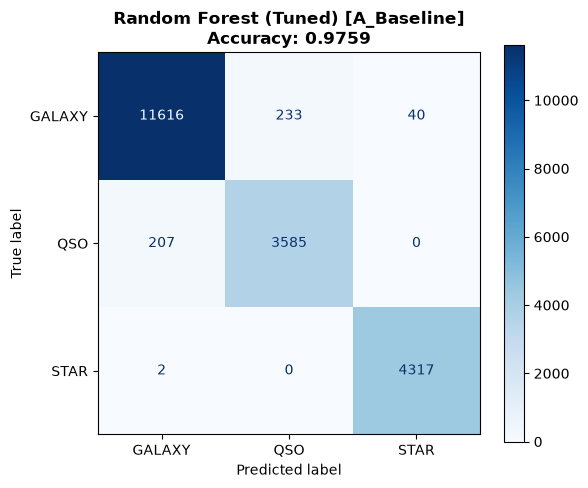


=== Tuning Random Forest  B_Ekstensif ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'min_samples_split': 14, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 12}
Best val score : 0.9772

-----------------------------------------------------------------
  MODEL: Random Forest (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9760 (98%)
   Paper Accuracy   : 98%
   Selisih          : -0.4%  Match

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.98      0.98     11889
         QSO       0.94      0.95      0.94      3792
        STAR       0.99      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



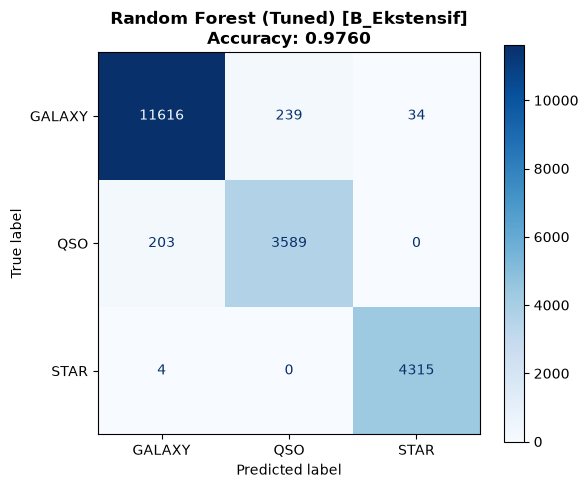


=== Tuning Random Forest  C_Spasial ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 15}
Best val score : 0.6361

-----------------------------------------------------------------
  MODEL: Random Forest (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.6028 (60%)
   Paper Accuracy   : 98%
   Selisih          : -37.7%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.79      0.68      0.73     11889
         QSO       0.33      0.51      0.40      3792
        STAR       0.51      0.47      0.49      4319

    accuracy                           0.60     20000
   macro avg       0.55      0.55      0.54     20000
weighted avg       0.65      0.60      0.62     20000



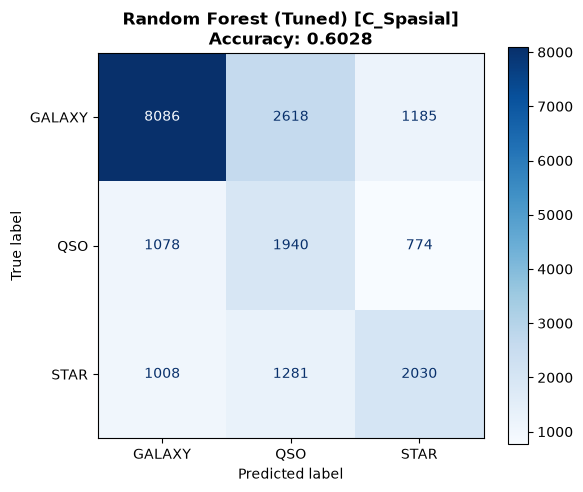


=== Tuning Random Forest  D_Fotometri ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 15}
Best val score : 0.8714

-----------------------------------------------------------------
  MODEL: Random Forest (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8608 (86%)
   Paper Accuracy   : 98%
   Selisih          : -11.9%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.93      0.90      0.91     11889
         QSO       0.78      0.82      0.80      3792
        STAR       0.77      0.77      0.77      4319

    accuracy                           0.86     20000
   macro avg       0.82      0.83      0.83     20000
weighted avg       0.86      0.86      0.86     20000



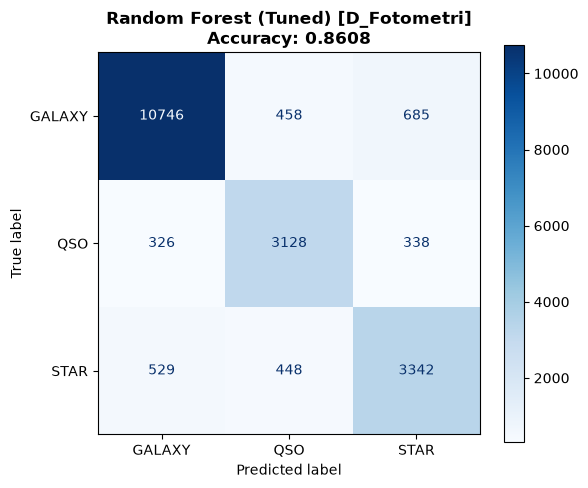


=== Tuning Random Forest  E_Astrometri_Kinematik ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 15}
Best val score : 0.9434

-----------------------------------------------------------------
  MODEL: Random Forest (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9512 (95%)
   Paper Accuracy   : 98%
   Selisih          : -2.9%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.96      0.96      0.96     11889
         QSO       0.89      0.86      0.87      3792
        STAR       0.99      1.00      1.00      4319

    accuracy                           0.95     20000
   macro avg       0.95      0.94      0.94     20000
weighted avg       0.95      0.95      0.95     20000



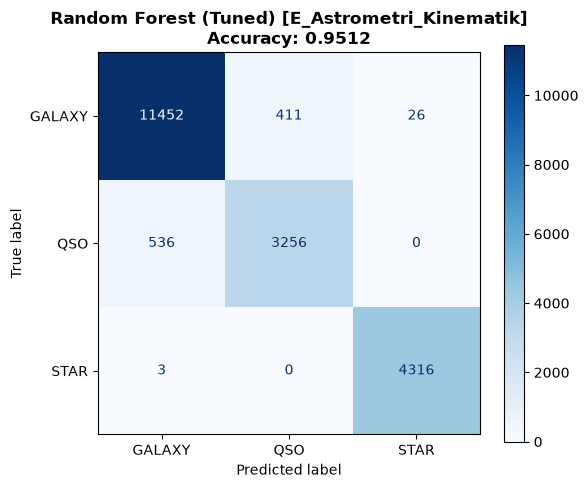

In [14]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'max_depth': [6, 8, 10, 12, 15],
    'min_samples_split': [10, 14, 20],
    'min_samples_leaf': [4, 6, 8],
    'max_features': ['log2', 'sqrt']
}

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning Random Forest  {nama_skenario} ===')
    
    # Tuning pakai X_train, evaluasi sementara pakai X_val
    rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
    search = RandomizedSearchCV(
        rf_base, param_dist,
        n_iter=20, cv=3,
        scoring='accuracy',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(data['X_train'], data['y_train'])
    
    print(f'Best params : {search.best_params_}')
    print(f'Best val score : {search.best_score_:.4f}')
    

    best_rf = search.best_estimator_
    evaluate_model(
        best_rf, 'Random Forest (Tuned)',
        data['X_train'], data['X_test'],
        data['y_train'], data['y_test'],
        skenario_name=nama_skenario,
        paper_accuracy=98
    )

**Kesimpulan**

| Skenario | Fitur | Test Accuracy | Paper Accuracy | Selisih |
|----------|-------|--------------|----------------|---------|
| A_Baseline | redshift, u, g, r, i, z | 97.59% | 98% | -0.4% |
| B_Ekstensif | redshift, u, g, r, i, z, alpha, delta | 97.60% | 98% | -0.4% |
| C_Spasial | alpha, delta | 60.28% | 98% | -37.7% |
| D_Fotometri | u, g, r, i, z | 86.08% | 98% | -11.9% |
| E_Astrometri_Kinematik | redshift, alpha, delta | 95.12% | 98% | -2.9% |

**Analisis per skenario:**

**A_Baseline & B_Ekstensif:** 
Keduanya menghasilkan akurasi tertinggi dan hampir identik (~97.6%), mengkonfirmasi bahwa penambahan fitur `alpha` dan `delta` pada skenario B tidak memberikan peningkatan signifikan. Ini menunjukkan bahwa `redshift` dan fitur fotometri (u, g, r, i, z) sudah cukup informatif untuk klasifikasi.

**C_Spasial:** 
Performa terburuk dengan akurasi hanya 60.28%, jauh di bawah paper. Koordinat langit (`alpha`, `delta`) saja tidak cukup untuk membedakan jenis objek stellar, posisi di langit tidak mencerminkan karakteristik fisik objek.

**D_Fotometri:**
Tanpa `redshift`, akurasi turun ke 86.08%. Ini membuktikan bahwa `redshift` adalah **fitur paling penting** dalam dataset ini, khususnya untuk membedakan QSO dari Galaxy dan Star.

**E_Astrometri_Kinematik:** 
Kombinasi `redshift`, `alpha`, `delta` menghasilkan 95.12%, cukup baik meski tanpa fitur fotometri. Ini semakin menegaskan dominasi `redshift` sebagai fitur pembeda utama.

**Kesimpulan utama:** 
`redshift` adalah fitur yang paling menentukan performa klasifikasi. Skenario terbaik adalah A_Baseline dan B_Ekstensif, dengan skenario B tidak memberikan nilai tambah berarti dibanding A.

### **10.2 K-Nearest Neighbors (KNN) - Tuned**

Cell ini melatih dan mengevaluasi model **K-Nearest Neighbors (KNN)** dengan hyperparameter tuning menggunakan `RandomizedSearchCV` pada seluruh 5 skenario fitur.

**Hyperparameter yang di-tuning:**
- `n_neighbors`: jumlah tetangga terdekat yang dipertimbangkan untuk voting klasifikasi
- `weights`: skema pembobotan, `uniform` berarti semua tetangga bobotnya sama, `distance` berarti tetangga lebih dekat diberi bobot lebih besar
- `p`: metrik jarak, `p=1` menggunakan Manhattan distance dan `p=2` menggunakan Euclidean distance
- `leaf_size`: ukuran leaf pada struktur BallTree/KDTree yang mempengaruhi kecepatan komputasi, namun tidak mempengaruhi akurasi

**Strategi subsample:**
KNN memiliki kompleksitas komputasi yang tinggi pada dataset besar karena harus menghitung jarak ke seluruh data training untuk setiap prediksi. Oleh karena itu, proses tuning dilakukan pada **subsample 10.000 data** dari training set untuk efisiensi waktu. Setelah best params ditemukan, model di-refit ulang menggunakan **full training data** sebelum dievaluasi pada data test.

**Proses tuning:**
- `RandomizedSearchCV` dengan `n_iter=10` mencoba 10 kombinasi hyperparameter secara acak
- `cv=3` berarti setiap kombinasi dievaluasi dengan 3-fold cross validation
- `n_jobs=-1` memanfaatkan seluruh core CPU agar proses lebih cepat

**Evaluasi:**
`best_estimator_` hasil tuning di-refit pada full training data, kemudian dievaluasi menggunakan `evaluate_model()` dan dibandingkan dengan akurasi paper referensi sebesar **97%**.


=== Tuning KNN  A_Baseline ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'weights': 'distance', 'p': 1, 'n_neighbors': 5, 'leaf_size': 60}
Best val score : 0.9587

-----------------------------------------------------------------
  MODEL: KNN (Tuned) [A_Baseline]
-----------------------------------------------------------------

Test Set Accuracy : 0.9565 (96%)
   Paper Accuracy   : 97%
   Selisih          : -1.4%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.95      0.96     11889
         QSO       0.89      0.94      0.92      3792
        STAR       0.95      1.00      0.97      4319

    accuracy                           0.96     20000
   macro avg       0.94      0.96      0.95     20000
weighted avg       0.96      0.96      0.96     20000



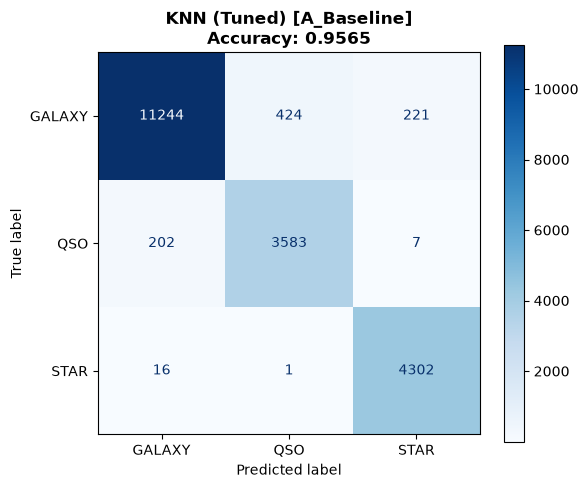


=== Tuning KNN  B_Ekstensif ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'weights': 'distance', 'p': 1, 'n_neighbors': 5, 'leaf_size': 60}
Best val score : 0.9273

-----------------------------------------------------------------
  MODEL: KNN (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9411 (94%)
   Paper Accuracy   : 97%
   Selisih          : -2.9%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.97      0.93      0.95     11889
         QSO       0.91      0.93      0.92      3792
        STAR       0.89      0.99      0.94      4319

    accuracy                           0.94     20000
   macro avg       0.92      0.95      0.94     20000
weighted avg       0.94      0.94      0.94     20000



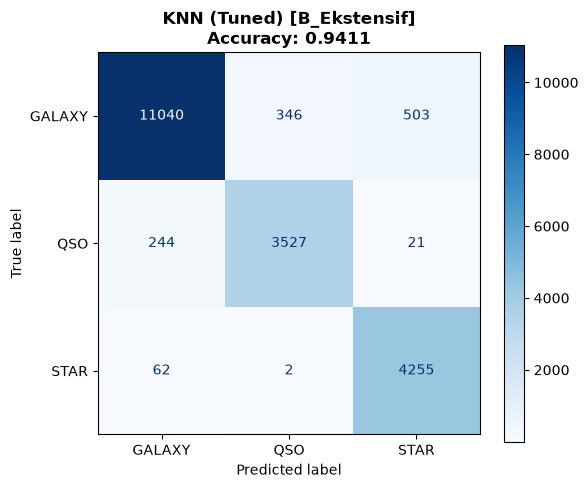


=== Tuning KNN  C_Spasial ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'weights': 'distance', 'p': 2, 'n_neighbors': 10, 'leaf_size': 60}
Best val score : 0.5530

-----------------------------------------------------------------
  MODEL: KNN (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.6139 (61%)
   Paper Accuracy   : 97%
   Selisih          : -35.6%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.83      0.69      0.76     11889
         QSO       0.35      0.47      0.40      3792
        STAR       0.45      0.52      0.48      4319

    accuracy                           0.61     20000
   macro avg       0.54      0.56      0.55     20000
weighted avg       0.66      0.61      0.63     20000



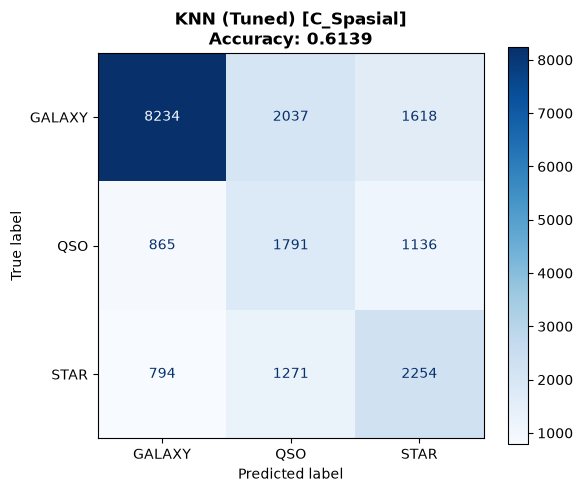


=== Tuning KNN  D_Fotometri ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'weights': 'distance', 'p': 1, 'n_neighbors': 5, 'leaf_size': 60}
Best val score : 0.7994

-----------------------------------------------------------------
  MODEL: KNN (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8109 (81%)
   Paper Accuracy   : 97%
   Selisih          : -15.9%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.92      0.85      0.88     11889
         QSO       0.68      0.78      0.73      3792
        STAR       0.67      0.73      0.70      4319

    accuracy                           0.81     20000
   macro avg       0.76      0.79      0.77     20000
weighted avg       0.82      0.81      0.81     20000



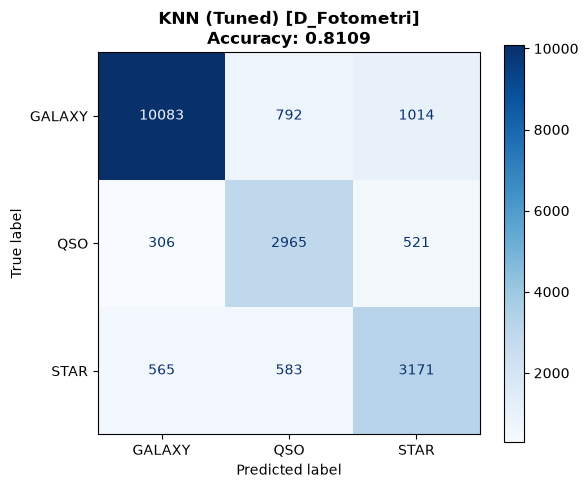


=== Tuning KNN  E_Astrometri_Kinematik ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'weights': 'distance', 'p': 1, 'n_neighbors': 5, 'leaf_size': 60}
Best val score : 0.9106

-----------------------------------------------------------------
  MODEL: KNN (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9157 (92%)
   Paper Accuracy   : 97%
   Selisih          : -5.4%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.95      0.91      0.93     11889
         QSO       0.79      0.85      0.82      3792
        STAR       0.94      1.00      0.97      4319

    accuracy                           0.92     20000
   macro avg       0.89      0.92      0.91     20000
weighted avg       0.92      0.92      0.92     20000



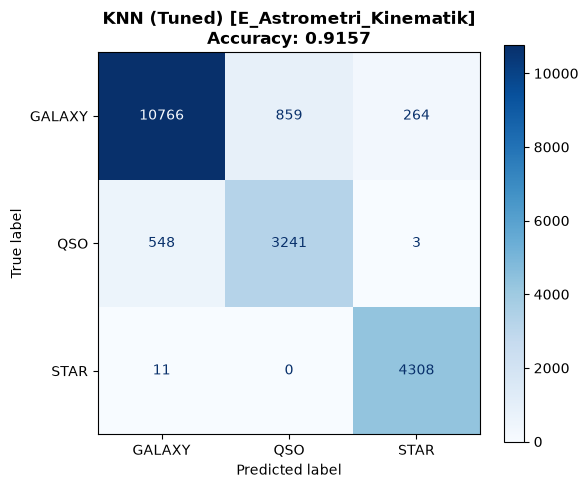

In [12]:
param_dist = {
    'n_neighbors': [5, 10, 15, 19, 25, 30],
    'weights': ['uniform', 'distance'],
    'p': [1, 2],
    'leaf_size': [20, 30, 49, 60]
}

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning KNN  {nama_skenario} ===')

    # Subsample karena KNN lambat di data besar
    X_sub = data['X_train'].sample(n=10000, random_state=RANDOM_STATE)
    y_sub = data['y_train'].loc[X_sub.index]

    knn_base = KNeighborsClassifier()
    search = RandomizedSearchCV(
        knn_base, param_dist,
        n_iter=10, cv=3,
        scoring='accuracy',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_sub, y_sub)

    print(f'Best params    : {search.best_params_}')
    print(f'Best val score : {search.best_score_:.4f}')

    # Refit full data dengan best params
    best_knn = search.best_estimator_
    best_knn.fit(data['X_train'], data['y_train'])
    evaluate_model(
        best_knn, 'KNN (Tuned)',
        data['X_train'], data['X_test'],
        data['y_train'], data['y_test'],
        skenario_name=nama_skenario,
        paper_accuracy=97
    )

**Kesimpulan**

| Skenario | Test Accuracy | Paper Accuracy | Selisih |
|----------|--------------|----------------|---------|
| A_Baseline | 95.65% | 97% | -1.4% |
| B_Ekstensif | 94.11% | 97% | -2.9% |
| C_Spasial | 61.39% | 97% | -35.6% |
| D_Fotometri | 81.09% | 97% | -15.9% |
| E_Astrometri_Kinematik | 91.57% | 97% | -5.4% |

**Kesimpulan:** 
- Skenario terbaik adalah **A_Baseline** (95.65%), sementara penambahan fitur `alpha` dan `delta` pada B justru menurunkan akurasi 
- KNN sensitif terhadap fitur yang tidak relevan karena menghitung jarak di semua dimensi. 
- Pola konsisten dengan Random Forest: **C_Spasial terburuk** dan `redshift` terbukti krusial. 
- Secara keseluruhan KNN masih di bawah paper di semua skenario.

### **10.3 Multilayer Perceptron (MLP)**

Cell ini melatih dan mengevaluasi model **Multilayer Perceptron (MLP)** dengan hyperparameter tuning menggunakan `RandomizedSearchCV` pada seluruh 5 skenario fitur.

**Hyperparameter yang di-tuning:**
- `hidden_layer_sizes`: arsitektur jaringan, menentukan jumlah layer dan neuron per layer
- `alpha`: parameter regularisasi L2 untuk mencegah overfitting
- `activation`: fungsi aktivasi tiap neuron, `relu` atau `tanh`
- `learning_rate_init`: learning rate awal untuk update bobot

**Proses tuning:**
- `RandomizedSearchCV` dengan `n_iter=10` dan `cv=3`
- `early_stopping=True` dan `validation_fraction=0.1`: MLP secara internal menyisihkan 10% data training sebagai validation set untuk menghentikan training otomatis jika tidak ada peningkatan, sehingga mencegah overfitting sekaligus mempercepat waktu training
- `n_jobs=-1` memanfaatkan seluruh core CPU

**Evaluasi:**
`best_estimator_` hasil tuning langsung dimasukkan ke `evaluate_model()` dan dibandingkan dengan akurasi paper referensi sebesar **97%**.


=== Tuning MLP  A_Baseline ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (100, 100, 100), 'alpha': 0.0001, 'activation': 'tanh'}
Best val score : 0.9710

-----------------------------------------------------------------
  MODEL: MLP (Tuned) [A_Baseline]
-----------------------------------------------------------------

Test Set Accuracy : 0.9698 (97%)
   Paper Accuracy   : 97%
   Selisih          : -0.0%  Match

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.97      0.97     11889
         QSO       0.93      0.95      0.94      3792
        STAR       0.97      1.00      0.98      4319

    accuracy                           0.97     20000
   macro avg       0.96      0.97      0.97     20000
weighted avg       0.97      0.97      0.97     20000



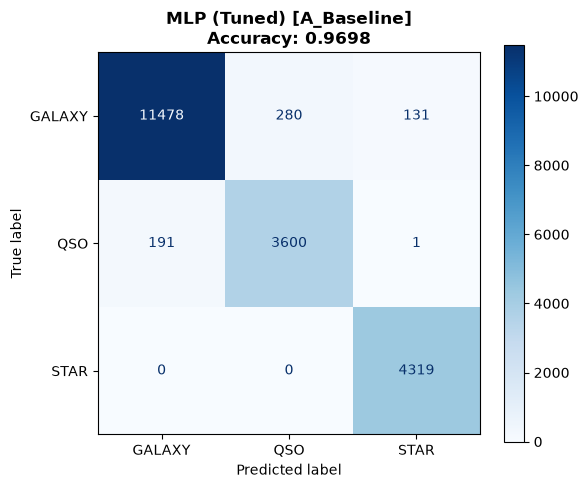


=== Tuning MLP  B_Ekstensif ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'learning_rate_init': 0.01, 'hidden_layer_sizes': (100, 100, 100), 'alpha': 0.0001, 'activation': 'relu'}
Best val score : 0.9721

-----------------------------------------------------------------
  MODEL: MLP (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9697 (97%)
   Paper Accuracy   : 97%
   Selisih          : -0.0%  Match

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.97      0.97     11889
         QSO       0.93      0.95      0.94      3792
        STAR       0.97      1.00      0.98      4319

    accuracy                           0.97     20000
   macro avg       0.96      0.97      0.97     20000
weighted avg       0.97      0.97      0.97     20000



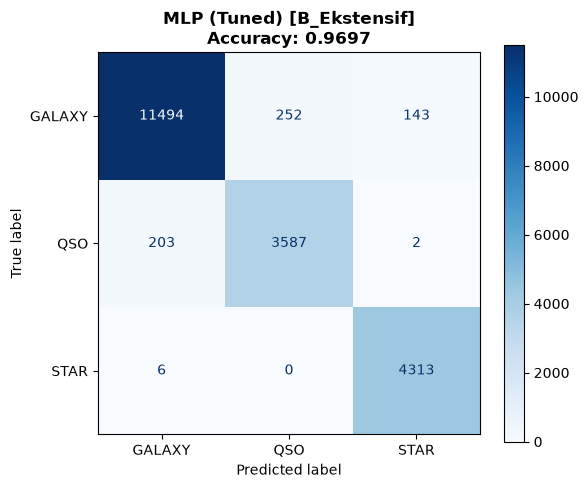


=== Tuning MLP  C_Spasial ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (100, 100, 100), 'alpha': 0.0001, 'activation': 'tanh'}
Best val score : 0.4959

-----------------------------------------------------------------
  MODEL: MLP (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.4984 (50%)
   Paper Accuracy   : 97%
   Selisih          : -47.2%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.74      0.51      0.61     11889
         QSO       0.28      0.51      0.36      3792
        STAR       0.40      0.45      0.42      4319

    accuracy                           0.50     20000
   macro avg       0.47      0.49      0.46     20000
weighted avg       0.58      0.50      0.52     20000



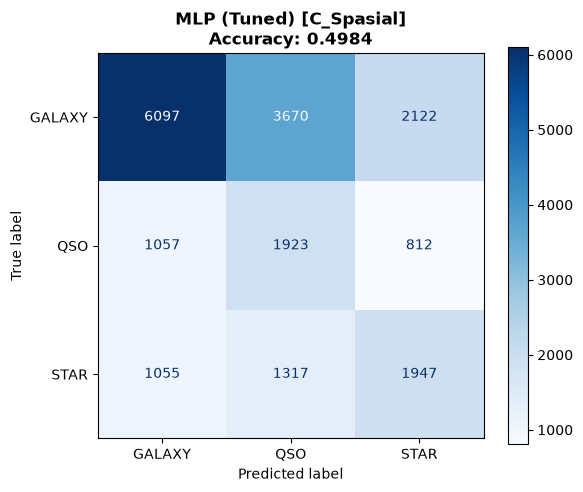


=== Tuning MLP  D_Fotometri ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (100, 100, 100), 'alpha': 0.001, 'activation': 'relu'}
Best val score : 0.8626

-----------------------------------------------------------------
  MODEL: MLP (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8741 (87%)
   Paper Accuracy   : 97%
   Selisih          : -9.6%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.94      0.91      0.92     11889
         QSO       0.78      0.86      0.81      3792
        STAR       0.80      0.80      0.80      4319

    accuracy                           0.87     20000
   macro avg       0.84      0.85      0.85     20000
weighted avg       0.88      0.87      0.88     20000



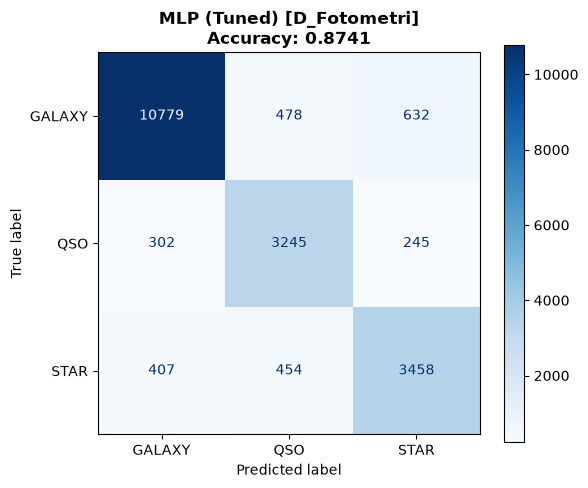


=== Tuning MLP  E_Astrometri_Kinematik ===
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params    : {'learning_rate_init': 0.01, 'hidden_layer_sizes': (100, 100, 100), 'alpha': 0.0001, 'activation': 'relu'}
Best val score : 0.9333

-----------------------------------------------------------------
  MODEL: MLP (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9405 (94%)
   Paper Accuracy   : 97%
   Selisih          : -3.0%  Lebih rendah

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.96      0.94      0.95     11889
         QSO       0.86      0.86      0.86      3792
        STAR       0.97      1.00      0.99      4319

    accuracy                           0.94     20000
   macro avg       0.93      0.94      0.93     20000
weighted avg       0.94      0.94      0.94     20000



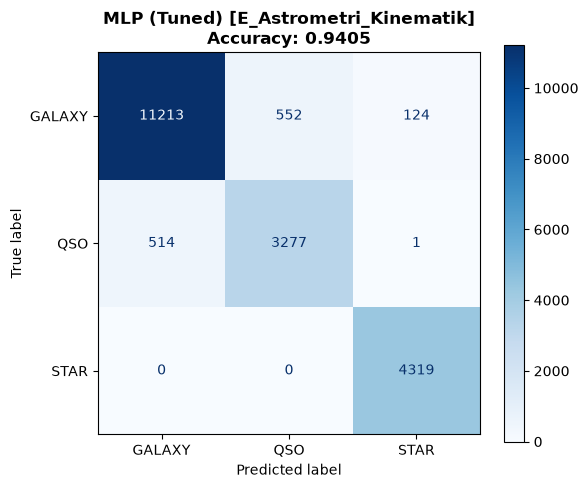

In [13]:
param_dist = {
    'hidden_layer_sizes': [(64, 64), (100, 100), (100, 100, 100), (128, 64, 32)],
    'alpha': [0.0001, 0.001, 0.01, 0.1],
    'activation': ['relu', 'tanh'],
    'learning_rate_init': [0.001, 0.01]
}

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning MLP  {nama_skenario} ===')

    mlp_base = MLPClassifier(
        max_iter=200,
        random_state=RANDOM_STATE,
        early_stopping=True,      # otomatis stop kalau ga improve
        validation_fraction=0.1   # pakai 10% train buat internal val
    )
    search = RandomizedSearchCV(
        mlp_base, param_dist,
        n_iter=10, cv=3,
        scoring='accuracy',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(data['X_train'], data['y_train'])

    print(f'Best params    : {search.best_params_}')
    print(f'Best val score : {search.best_score_:.4f}')

    evaluate_model(
        search.best_estimator_, 'MLP (Tuned)',
        data['X_train'], data['X_test'],
        data['y_train'], data['y_test'],
        skenario_name=nama_skenario,
        paper_accuracy=97
    )

**Kesimpulan**

| Skenario | Test Accuracy | Paper Accuracy | Selisih |
|----------|--------------|----------------|---------|
| A_Baseline | 96.98% | 97% | -0.0% |
| B_Ekstensif | 96.97% | 97% | -0.0% |
| C_Spasial | 49.84% | 97% | -47.2% |
| D_Fotometri | 87.41% | 97% | -9.6% |
| E_Astrometri_Kinematik | 94.05% | 97% | -3.0% |

**Kesimpulan:** 
- MLP adalah model pertama yang berhasil **match sempurna** dengan paper di skenario A dan B (97%). Arsitektur `(100, 100, 100)` konsisten terpilih sebagai best params di semua skenario, mengkonfirmasi bahwa pilihan paper sudah optimal. 
- Skenario C_Spasial menjadi yang terburuk dengan hanya 49.84%. Bahkan mendekati random guess untuk 3 kelas, semakin memperkuat bahwa koordinat spasial saja tidak memiliki daya diskriminatif yang cukup untuk klasifikasi objek stellar.

### **10.4 XGBoost (Tuned)**

Cell ini melatih dan mengevaluasi model **XGBoost** dengan hyperparameter tuning menggunakan `RandomizedSearchCV` pada seluruh 5 skenario fitur.

**Hyperparameter yang di-tuning:**
- `n_estimators`: jumlah pohon yang dibangun secara sekuensial
- `max_depth`: kedalaman maksimum tiap pohon
- `learning_rate`: ukuran langkah update bobot tiap iterasi, nilai kecil lebih stabil namun butuh lebih banyak pohon
- `subsample`: proporsi data training yang diambil secara acak untuk tiap pohon, mencegah overfitting
- `colsample_bytree`: proporsi fitur yang diambil secara acak untuk tiap pohon
- `min_child_weight`: minimum jumlah instance yang dibutuhkan di sebuah leaf node

**Label Encoding:**
XGBoost membutuhkan label target dalam format numerik, sehingga `LabelEncoder` digunakan untuk mengkonversi kelas (`GALAXY`, `QSO`, `STAR`) menjadi integer. `fit_transform` hanya dilakukan pada `y_train`, sedangkan `y_val` dan `y_test` menggunakan `transform` untuk mencegah data leakage.

**Proses tuning (2 tahap):**
- **Step 1** — `RandomizedSearchCV` dengan `n_iter=20` dan `cv=3` mencari best params tanpa early stopping
- **Step 2** — Model di-refit ulang menggunakan best params hasil tuning, kemudian dievaluasi pada data test menggunakan `evaluate_model()`


=== Tuning XGBoost  A_Baseline ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 9, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best val score : 0.9779

-----------------------------------------------------------------
  MODEL: XGBoost (Tuned) [A_Baseline]
-----------------------------------------------------------------

Test Set Accuracy : 0.9745 (97%)

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11889
           1       0.94      0.95      0.94      3792
           2       0.99      1.00      0.99      4319

    accuracy                           0.97     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.97      0.97      0.97     20000



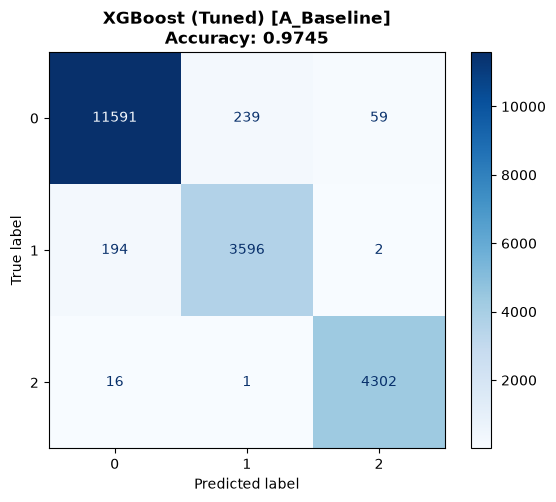


=== Tuning XGBoost  B_Ekstensif ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 9, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best val score : 0.9795

-----------------------------------------------------------------
  MODEL: XGBoost (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9766 (98%)

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11889
           1       0.94      0.95      0.95      3792
           2       0.99      1.00      0.99      4319

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



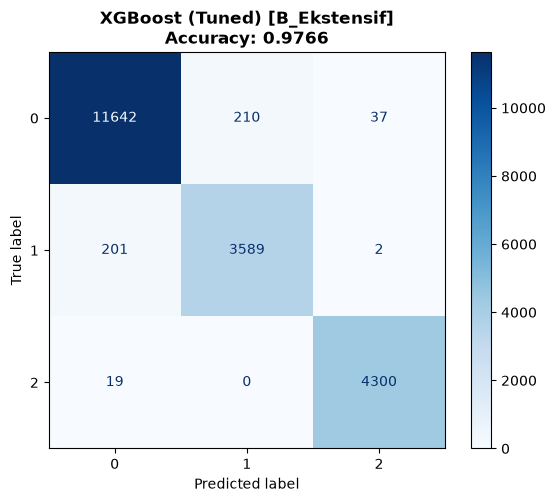


=== Tuning XGBoost  C_Spasial ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best val score : 0.5895

-----------------------------------------------------------------
  MODEL: XGBoost (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.5798 (58%)

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.64      0.70     11889
           1       0.32      0.50      0.39      3792
           2       0.47      0.48      0.48      4319

    accuracy                           0.58     20000
   macro avg       0.53      0.54      0.52     20000
weighted avg       0.63      0.58      0.60     20000



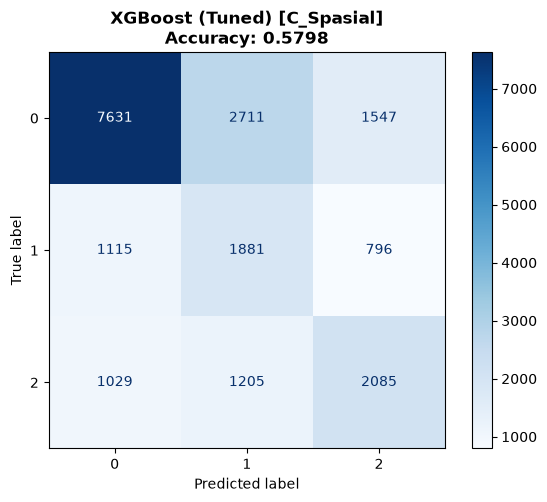


=== Tuning XGBoost  D_Fotometri ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 9, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best val score : 0.8726

-----------------------------------------------------------------
  MODEL: XGBoost (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8570 (86%)

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.91     11889
           1       0.77      0.82      0.79      3792
           2       0.75      0.78      0.77      4319

    accuracy                           0.86     20000
   macro avg       0.82      0.83      0.82     20000
weighted avg       0.86      0.86      0.86     20000



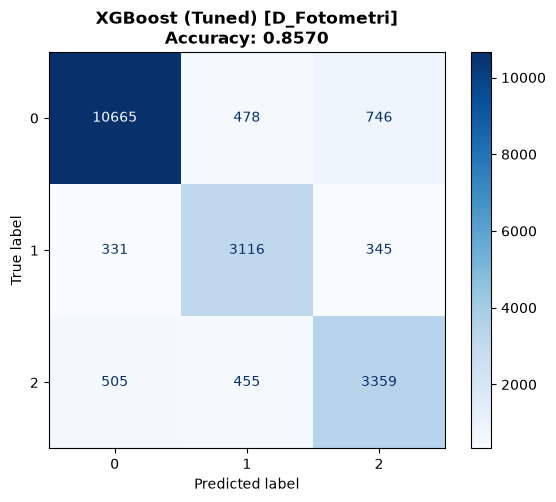


=== Tuning XGBoost  E_Astrometri_Kinematik ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best val score : 0.9416

-----------------------------------------------------------------
  MODEL: XGBoost (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9481 (95%)

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     11889
           1       0.88      0.86      0.87      3792
           2       0.99      0.99      0.99      4319

    accuracy                           0.95     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.95      0.95      0.95     20000



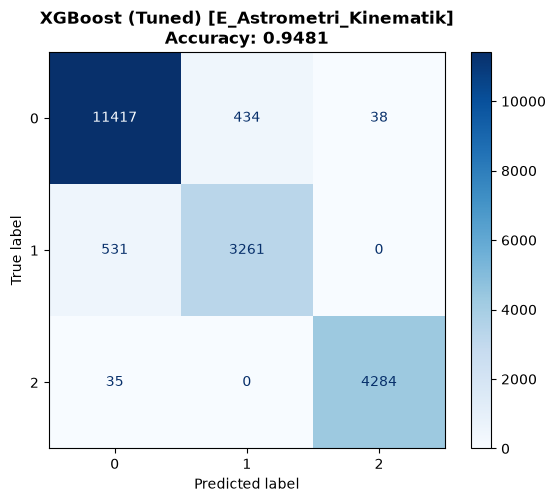

In [17]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning XGBoost  {nama_skenario} ===')

    le = LabelEncoder()
    y_train = le.fit_transform(data['y_train'])
    y_val   = le.transform(data['y_val'])
    y_test  = le.transform(data['y_test'])

    # Tuning dengan RandomizedSearchCV
    # Step 1  Tuning tanpa early stopping
    xgb_base = XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric='mlogloss',
        verbose=0
    )
    search = RandomizedSearchCV(
        xgb_base, param_dist,
        n_iter=20, cv=3,
        scoring='accuracy',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(data['X_train'], y_train)

    print(f'Best params    : {search.best_params_}')
    print(f'Best val score : {search.best_score_:.4f}')

    # Step 2  Refit dengan best params + early stopping pakai X_val
    best_xgb = XGBClassifier(
        **search.best_params_,
        random_state=RANDOM_STATE,
        eval_metric='mlogloss',
    )

    evaluate_model(
        best_xgb, 'XGBoost (Tuned)',
        data['X_train'], data['X_test'],
        y_train, y_test,
        skenario_name=nama_skenario
    )

**Kesimpulan**

| Skenario | Test Accuracy | Selisih vs RF | 
|----------|--------------|---------------|
| A_Baseline | 97.45% | -0.14% |
| B_Ekstensif | 97.66% | +0.06% |
| C_Spasial | 57.98% | -2.3% |
| D_Fotometri | 85.70% | -0.38% |
| E_Astrometri_Kinematik | 94.81% | -0.31% |

**Kesimpulan:** XGBoost menghasilkan performa yang sangat kompetitif dengan Random Forest di hampir semua skenario. **B_Ekstensif menjadi skenario terbaik** (97.66%), berbeda dengan RF dan KNN dimana penambahan `alpha` dan `delta` justru tidak membantu atau menurunkan performa. Ini menunjukkan XGBoost lebih mampu mengekstrak informasi dari fitur spasial dibanding model lain. Pola C_Spasial tetap konsisten sebagai skenario terburuk (57.98%).

### **10.5 LightGBM (Tuned)**

Cell ini melatih dan mengevaluasi model **LightGBM** dengan hyperparameter tuning menggunakan `RandomizedSearchCV` pada seluruh 5 skenario fitur.

**Hyperparameter yang di-tuning:**
- `n_estimators`: jumlah pohon yang dibangun secara sekuensial
- `max_depth`: kedalaman maksimum tiap pohon, nilai `-1` berarti tidak ada batasan
- `learning_rate`: ukuran langkah update bobot tiap iterasi
- `subsample`: proporsi data training yang diambil acak per pohon
- `colsample_bytree`: proporsi fitur yang diambil acak per pohon
- `min_child_samples`: minimum jumlah sampel di leaf node, parameter khas LightGBM pengganti `min_child_weight` pada XGBoost
- `reg_alpha`: regularisasi L1 untuk mencegah overfitting
- `reg_lambda`: regularisasi L2 untuk mencegah overfitting

**Proses tuning (2 tahap):**
- **Step 1** — `RandomizedSearchCV` dengan `n_iter=20` dan `cv=3` mencari best params
- **Step 2** — Model di-refit ulang dengan best params menggunakan `eval_set` dari `X_val` dan `early_stopping(10)` — ini adalah satu-satunya model selain XGBoost yang **benar-benar memanfaatkan validation set**, di mana training otomatis berhenti jika tidak ada peningkatan dalam 10 iterasi berturut-turut


=== Tuning LightGBM  A_Baseline ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best val score : 0.9792
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[209]	valid_0's multi_logloss: 0.0839658

-----------------------------------------------------------------
  MODEL: LightGBM (Tuned) [A_Baseline]
-----------------------------------------------------------------

Test Set Accuracy : 0.9741 (97%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.97      0.98     11889
         QSO       0.94      0.95      0.94      3792
        STAR       0.99      1.00      0.99      4319

    accuracy                           0.97     20000
   macro avg       0.97      0.97      0.97     20000
wei

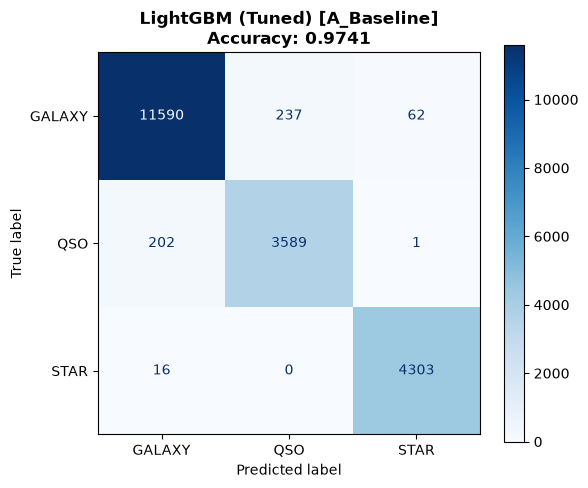


=== Tuning LightGBM  B_Ekstensif ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Best val score : 0.9801
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[179]	valid_0's multi_logloss: 0.0817537

-----------------------------------------------------------------
  MODEL: LightGBM (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9766 (98%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.98      0.98     11889
         QSO       0.94      0.95      0.95      3792
        STAR       0.99      1.00      0.99      4319

    accuracy                           0.98     20000
   macro avg       0.97      0.97      0.97     20000
w

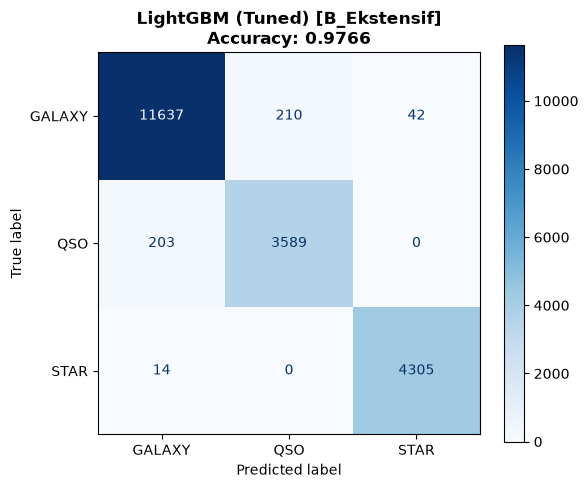


=== Tuning LightGBM  C_Spasial ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_samples': 10, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
Best val score : 0.6080
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[200]	valid_0's multi_logloss: 0.891222

-----------------------------------------------------------------
  MODEL: LightGBM (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.5980 (60%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.79      0.66      0.72     11889
         QSO       0.34      0.50      0.40      3792
        STAR       0.48      0.50      0.49      4319

    accuracy                           0.60     20000
   macro avg       0.54      0.56      0.54    

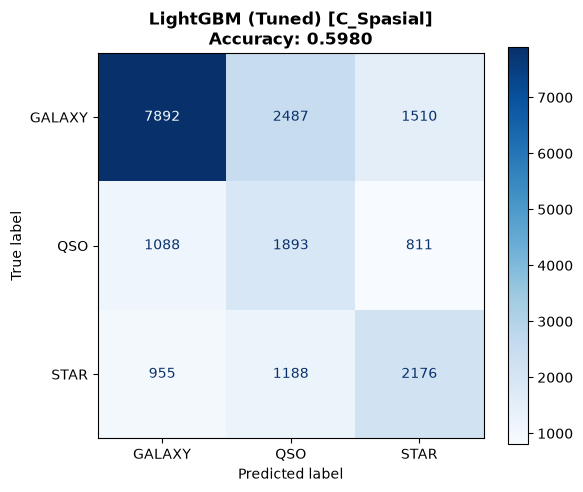


=== Tuning LightGBM  D_Fotometri ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_samples': 10, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
Best val score : 0.8672
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[199]	valid_0's multi_logloss: 0.389458

-----------------------------------------------------------------
  MODEL: LightGBM (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8597 (86%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.93      0.90      0.91     11889
         QSO       0.78      0.83      0.80      3792
        STAR       0.75      0.79      0.77      4319

    accuracy                           0.86     20000
   macro avg       0.82      0.84      0.83

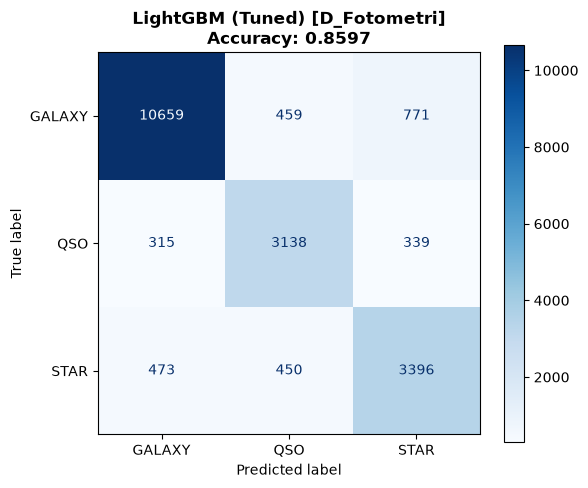


=== Tuning LightGBM  E_Astrometri_Kinematik ===
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params    : {'subsample': 1.0, 'reg_lambda': 0.1, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_samples': 10, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best val score : 0.9424
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[182]	valid_0's multi_logloss: 0.173907

-----------------------------------------------------------------
  MODEL: LightGBM (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9485 (95%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.95      0.96      0.96     11889
         QSO       0.88      0.86      0.87      3792
        STAR       0.99      1.00      0.99      4319

    accuracy                           0.95     20000
   macro avg       0.94      0.94   

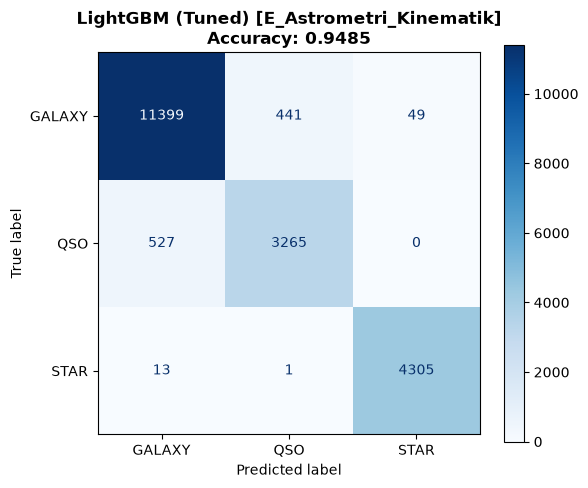

In [19]:
from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb
from lightgbm import LGBMClassifier

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 9, -1],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_samples': [10, 20, 30, 50],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning LightGBM  {nama_skenario} ===')

    # Step 1  Tuning dengan RandomizedSearchCV
    lgb_base = LGBMClassifier(
        random_state=RANDOM_STATE,
        verbose=-1
    )
    search = RandomizedSearchCV(
        lgb_base, param_dist,
        n_iter=20, cv=3,
        scoring='accuracy',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(data['X_train'], data['y_train'])

    print(f'Best params    : {search.best_params_}')
    print(f'Best val score : {search.best_score_:.4f}')

    # Step 2  Refit dengan best params + early stopping pakai X_val
    best_lgb = LGBMClassifier(
        **search.best_params_,
        random_state=RANDOM_STATE,
        verbose=-1
    )
    best_lgb.fit(
        data['X_train'], data['y_train'],
        eval_set=[(data['X_val'], data['y_val'])],  # X_val kepake!
        callbacks=[lgb.early_stopping(10), lgb.log_evaluation(-1)]
    )

    evaluate_model(
        best_lgb, 'LightGBM (Tuned)',
        data['X_train'], data['X_test'],
        data['y_train'], data['y_test'],
        skenario_name=nama_skenario
    )

**Kesimpulan**

| Skenario | Test Accuracy | Early Stopping |
|----------|--------------|----------------|
| A_Baseline | 97.41% | iter ke-209 |
| B_Ekstensif | 97.66% | iter ke-179 |
| C_Spasial | 59.80% | tidak triggered |
| D_Fotometri | 85.97% | tidak triggered |
| E_Astrometri_Kinematik | 94.85% | iter ke-182 |

**Kesimpulan:** 
- LightGBM menghasilkan performa yang hampir identik dengan XGBoost di semua skenario. **B_Ekstensif kembali menjadi terbaik** (97.66%), konsisten dengan XGBoost. Hal ini mengkonfirmasi bahwa model berbasis gradient boosting lebih mampu memanfaatkan fitur spasial `alpha` dan `delta` dibanding model lain. 
- Kolom early stopping menunjukkan informasi: skenario C dan D **tidak memicu early stopping**, artinya model terus belajar hingga iterasi terakhir namun tetap tidak mampu menemukan pola yang cukup kuat
- Bukti lebih lanjut bahwa keterbatasan performa di skenario tersebut bukan soal overfitting, melainkan memang **fiturnya tidak cukup informatif**.

### **10.6 Custom Dense Neural Network (Tuned)**

Cell ini melatih dan mengevaluasi **Custom Dense Neural Network (DNN)** menggunakan TensorFlow/Keras dengan tuning manual via `X_val` pada seluruh 5 skenario fitur.

**Arsitektur (tiap layer):** Dense + BatchNormalization + Dropout → Dense(3) Softmax

**Teknik regularisasi:**
- `Dropout`: mencegah overfitting dengan menonaktifkan neuron secara acak selama training
- `Batch Normalization`: menstabilkan distribusi input antar layer dan mempercepat konvergensi

**Proses tuning (manual grid search):**
6 kombinasi konfigurasi diuji mencakup variasi `units`, `dropout_rate`, `learning_rate`, `batch_size`, dan `epochs`. Setiap konfigurasi dievaluasi pada `X_val`, dan konfigurasi dengan `val_accuracy` tertinggi dipilih sebagai best config per skenario.

**Training final:**
Model dibangun ulang menggunakan best config tiap skenario melalui `KerasWrapper`: sebuah wrapper custom yang menyesuaikan interface DNN agar kompatibel dengan fungsi `evaluate_model()`.


=== Tuning Custom DNN  A_Baseline ===
  units=[128, 64] | dropout=0.2 | lr=0.001 | bs=256 | ep=30  val_acc=0.9722
  units=[128, 64] | dropout=0.3 | lr=0.001 | bs=256 | ep=30  val_acc=0.9703
  units=[128, 64, 32] | dropout=0.2 | lr=0.001 | bs=256 | ep=50  val_acc=0.9735
  units=[128, 64, 32] | dropout=0.3 | lr=0.0005 | bs=128 | ep=50  val_acc=0.9730
  units=[256, 128, 64] | dropout=0.3 | lr=0.001 | bs=256 | ep=30  val_acc=0.9732
  units=[256, 128, 64] | dropout=0.2 | lr=0.0005 | bs=128 | ep=50  val_acc=0.9721

Best DNN config [A_Baseline]: {'units': [128, 64, 32], 'dropout': 0.2, 'lr': 0.001, 'batch_size': 256, 'epochs': 50}
Best val accuracy: 0.9735

=== Tuning Custom DNN  B_Ekstensif ===
  units=[128, 64] | dropout=0.2 | lr=0.001 | bs=256 | ep=30  val_acc=0.9654
  units=[128, 64] | dropout=0.3 | lr=0.001 | bs=256 | ep=30  val_acc=0.9646
  units=[128, 64, 32] | dropout=0.2 | lr=0.001 | bs=256 | ep=50  val_acc=0.9685
  units=[128, 64, 32] | dropout=0.3 | lr=0.0005 | bs=128 | ep=50  val

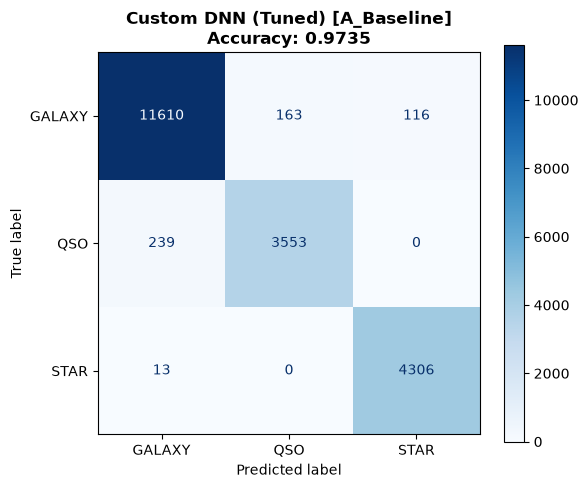


-----------------------------------------------------------------
  MODEL: Custom DNN (Tuned) [B_Ekstensif]
-----------------------------------------------------------------

Test Set Accuracy : 0.9662 (97%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.96      0.97     11889
         QSO       0.91      0.95      0.93      3792
        STAR       0.97      1.00      0.99      4319

    accuracy                           0.97     20000
   macro avg       0.96      0.97      0.96     20000
weighted avg       0.97      0.97      0.97     20000



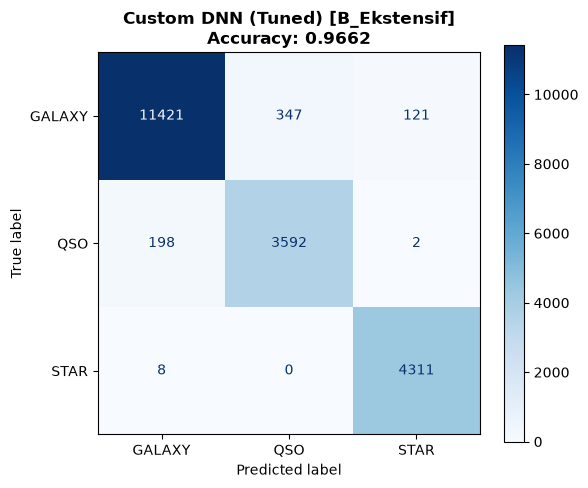


-----------------------------------------------------------------
  MODEL: Custom DNN (Tuned) [C_Spasial]
-----------------------------------------------------------------

Test Set Accuracy : 0.4724 (47%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.72      0.48      0.58     11889
         QSO       0.25      0.55      0.35      3792
        STAR       0.43      0.37      0.40      4319

    accuracy                           0.47     20000
   macro avg       0.47      0.47      0.44     20000
weighted avg       0.57      0.47      0.50     20000



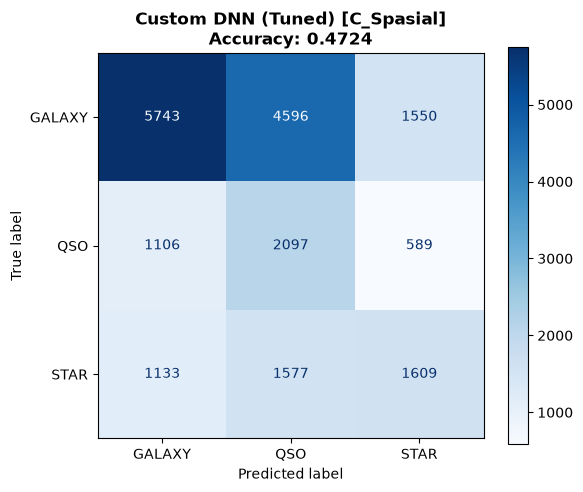


-----------------------------------------------------------------
  MODEL: Custom DNN (Tuned) [D_Fotometri]
-----------------------------------------------------------------

Test Set Accuracy : 0.8568 (86%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.91      0.93      0.92     11889
         QSO       0.74      0.81      0.78      3792
        STAR       0.82      0.70      0.76      4319

    accuracy                           0.86     20000
   macro avg       0.82      0.81      0.82     20000
weighted avg       0.86      0.86      0.86     20000



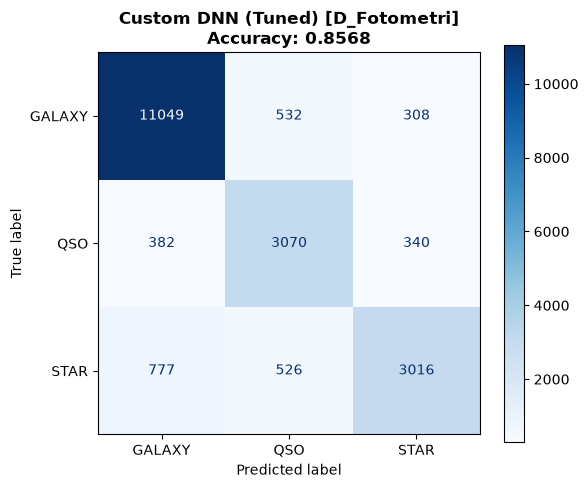


-----------------------------------------------------------------
  MODEL: Custom DNN (Tuned) [E_Astrometri_Kinematik]
-----------------------------------------------------------------

Test Set Accuracy : 0.9453 (95%)

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.95      0.95      0.95     11889
         QSO       0.88      0.86      0.87      3792
        STAR       0.97      1.00      0.99      4319

    accuracy                           0.95     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.94      0.95      0.94     20000



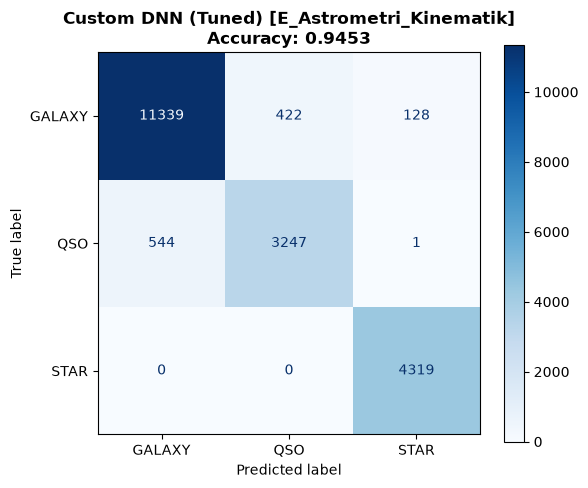

In [ ]:
# DNN HYPERPARAMETER TUNING  manual grid search via X_val
dnn_candidate_configs = [
    {'units': [128, 64],       'dropout': 0.2, 'lr': 0.001,  'batch_size': 256, 'epochs': 30},
    {'units': [128, 64],       'dropout': 0.3, 'lr': 0.001,  'batch_size': 256, 'epochs': 30},
    {'units': [128, 64, 32],   'dropout': 0.2, 'lr': 0.001,  'batch_size': 256, 'epochs': 50},
    {'units': [128, 64, 32],   'dropout': 0.3, 'lr': 0.0005, 'batch_size': 128, 'epochs': 50},
    {'units': [256, 128, 64],  'dropout': 0.3, 'lr': 0.001,  'batch_size': 256, 'epochs': 30},
    {'units': [256, 128, 64],  'dropout': 0.2, 'lr': 0.0005, 'batch_size': 128, 'epochs': 50},
]

best_dnn_params = {}

def build_dnn_custom(input_dim, units, dropout_rate, lr):
    """Build DNN dengan konfigurasi yang bisa dikustomisasi."""
    layer_list = [layers.Input(shape=(input_dim,))]
    for u in units:
        layer_list.extend([
            layers.Dense(u, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(dropout_rate)
        ])
    layer_list.append(layers.Dense(3, activation='softmax'))
    model = keras.Sequential(layer_list)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Label encoder khusus untuk DNN tuning
from sklearn.preprocessing import LabelEncoder as _LE

for nama_skenario, data in final_data.items():
    print(f'\n=== Tuning Custom DNN  {nama_skenario} ===')

    le_dnn = _LE()
    y_tr_enc = le_dnn.fit_transform(data['y_train'])
    y_vl_enc = le_dnn.transform(data['y_val'])

    best_val_acc = -1
    best_cfg = None

    for cfg in dnn_candidate_configs:
        tf.random.set_seed(RANDOM_STATE)
        m = build_dnn_custom(
            data['X_train'].shape[1],
            units=cfg['units'],
            dropout_rate=cfg['dropout'],
            lr=cfg['lr']
        )
        m.fit(
            data['X_train'], y_tr_enc,
            epochs=cfg['epochs'],
            batch_size=cfg['batch_size'],
            verbose=0
        )
        _, val_acc = m.evaluate(data['X_val'], y_vl_enc, verbose=0)
        print(f"  units={cfg['units']} | dropout={cfg['dropout']} | "
              f"lr={cfg['lr']} | bs={cfg['batch_size']} | ep={cfg['epochs']} "
              f" val_acc={val_acc:.4f}")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_cfg = cfg

    best_dnn_params[nama_skenario] = best_cfg
    print(f'\nBest DNN config [{nama_skenario}]: {best_cfg}')
    print(f'Best val accuracy: {best_val_acc:.4f}')

print('\n DNN tuning selesai  best_dnn_params tersimpan')
print()
for sk, cfg in best_dnn_params.items():
    print(f'  {sk}: {cfg}')


# TRAINING FINAL Custom DNN menggunakan best params per skenario
class KerasWrapper:
    def __init__(self, build_fn, epochs=30, batch_size=256, verbose=0):
        self.build_fn = build_fn
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose
        self.model_ = None
        self.classes_ = None
        self.label_encoder_ = None

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.label_encoder_ = {label: idx for idx, label in enumerate(self.classes_)}
        y_int = np.array([self.label_encoder_[label] for label in y])
        self.model_ = self.build_fn(X.shape[1])
        self.model_.fit(
            X, y_int,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=self.verbose
        )
        return self

    def predict(self, X):
        proba = self.model_.predict(X, verbose=0)
        y_pred_int = np.argmax(proba, axis=1)
        inv_map = {v: k for k, v in self.label_encoder_.items()}
        return np.array([inv_map[i] for i in y_pred_int])


def build_dnn(input_dim):
    """Build DNN dengan arsitektur default (128-64)  dipakai KerasWrapper."""
    model = keras.Sequential([
        layers.Dense(128, activation='relu', input_shape=(input_dim,)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


# Training final: gunakan best config per skenario dari tuning
for nama_skenario, data in final_data.items():
    cfg = best_dnn_params[nama_skenario]

    def make_build_fn(units, dropout_rate, lr):
        def build_fn(input_dim):
            return build_dnn_custom(input_dim, units=units,
                                    dropout_rate=dropout_rate, lr=lr)
        return build_fn

    dnn = KerasWrapper(
        build_fn=make_build_fn(cfg['units'], cfg['dropout'], cfg['lr']),
        epochs=cfg['epochs'],
        batch_size=cfg['batch_size'],
        verbose=0
    )
    evaluate_model(
        dnn, 'Custom DNN (Tuned)',
        data['X_train'], data['X_test'],
        data['y_train'], data['y_test'],
        skenario_name=nama_skenario
    )

**Kesimpulan**

| Skenario | Best Config | Best Val Acc | Test Accuracy |
|----------|-------------|--------------|---------------|
| A_Baseline | [128,64,32] dropout=0.2 lr=0.001 | 97.35% | 97.35% |
| B_Ekstensif | [256,128,64] dropout=0.3 lr=0.001 | 96.86% | 96.62% |
| C_Spasial | [256,128,64] dropout=0.2 lr=0.0005 | 48.57% | 47.24% |
| D_Fotometri | [128,64] dropout=0.3 lr=0.001 | 86.08% | 85.68% |
| E_Astrometri_Kinematik | [256,128,64] dropout=0.2 lr=0.0005 | 94.89% | 94.53% |

**Kesimpulan:** 
- DNN menghasilkan performa kompetitif di A_Baseline (97.35%) namun justru **B_Ekstensif menurun** dibanding A, berbeda dengan XGBoost dan LightGBM yang diuntungkan oleh penambahan fitur spasial. 
- Ini menunjukkan DNN lebih sensitif terhadap fitur yang kurang relevan.
- C_Spasial kembali menjadi yang terburuk (47.24%), bahkan di bawah random guess, mengkonfirmasi secara konsisten bahwa koordinat langit tidak cukup untuk klasifikasi objek stellar di semua jenis model sekalipun.

## **11. Ringkasan Hasil Semua Model & Skenario**

In [ ]:
df_results = pd.DataFrame(results_summary).T.reset_index()
df_results.columns = [
    'Model & Skenario', 'Test Accuracy (%)', 'Paper Accuracy (%)',
    'Precision (macro)', 'Recall (macro)', 'F1-Score (macro)'
]

# Pisahkan nama model dan skenario untuk sorting yang lebih baik
df_results[['Model', 'Skenario']] = df_results['Model & Skenario'].str.extract(
    r'^(.+?) \[(.+)\]$'
)

# Sort: skenario dulu, lalu model
df_results = df_results.sort_values(['Skenario', 'Model']).reset_index(drop=True)

print('=' * 110)
print('  RINGKASAN HASIL  Semua Model di Semua Skenario Fitur')
print('=' * 110)
print(f'  Total entri: {len(df_results)} (target: 6 model × 5 skenario = 30)')
print('=' * 110)

# Tampilkan tanpa kolom bantu
display_cols = ['Model & Skenario', 'Test Accuracy (%)', 'Paper Accuracy (%)',
                'Precision (macro)', 'Recall (macro)', 'F1-Score (macro)']
print(df_results[display_cols].to_string(index=False))
print('=' * 110)

# Cek apakah ada model/skenario yang belum jalan
expected_models = [
    'Random Forest (Tuned)', 'KNN (Tuned)', 'MLP (Tuned)',
    'XGBoost (Tuned)', 'LightGBM (Tuned)', 'Custom DNN (Tuned)'
]
expected_scenarios = list(final_data.keys())

missing = []
for m in expected_models:
    for s in expected_scenarios:
        key = f'{m} [{s}]'
        if key not in results_summary:
            missing.append(key)

if missing:
    print(f'\n MISSING ENTRIES ({len(missing)}):')
    for m in missing:
        print(f'   - {m}')
else:
    print('\nSemua 30 entri (6 model × 5 skenario) berhasil direkam')


  RINGKASAN HASIL  Semua Model di Semua Skenario Fitur
  Total entri: 30 (target: 8 model × 5 skenario = 40)
                              Model & Skenario Test Accuracy (%) Paper Accuracy (%) Precision (macro) Recall (macro) F1-Score (macro)
               Custom DNN (Tuned) [A_Baseline]             97.34                  -             96.96          97.02            96.98
                      KNN (Tuned) [A_Baseline]             95.64               97.0             94.15          96.22            95.14
                 LightGBM (Tuned) [A_Baseline]             97.41                  -             96.84          97.25            97.04
                      MLP (Tuned) [A_Baseline]             96.98               97.0             96.06          97.16             96.6
            Random Forest (Tuned) [A_Baseline]             97.59               98.0             97.07           97.4            97.23
                  XGBoost (Tuned) [A_Baseline]             97.45                  -    

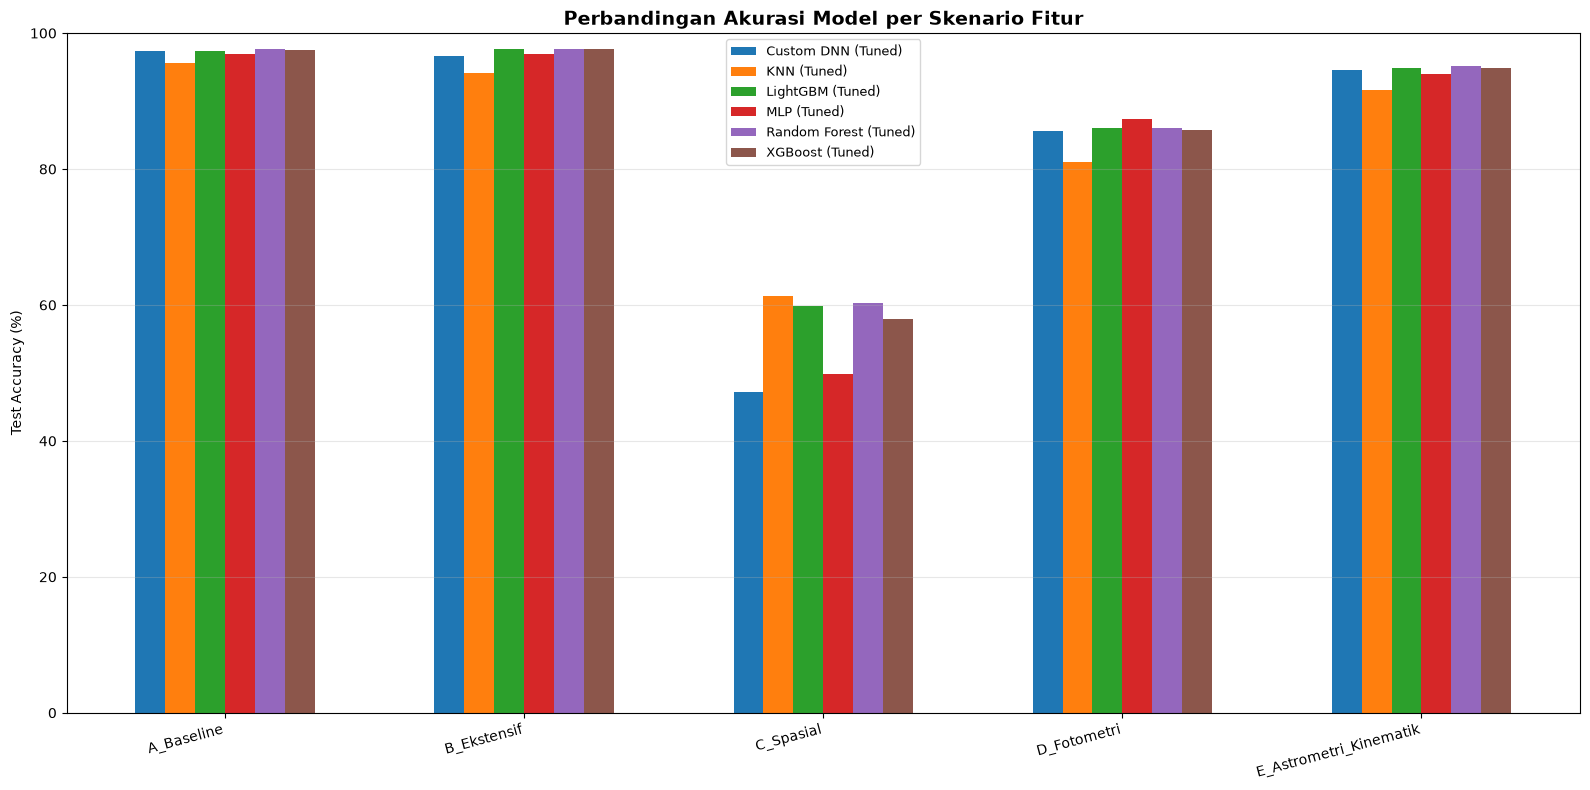

Grafik perbandingan selesai


In [22]:
# Visualisasi perbandingan akurasi per skenario
fig, ax = plt.subplots(figsize=(16, 8))

skenario_list = list(final_data.keys())
models_in_summary = df_results['Model & Skenario'].apply(
    lambda x: x.split(' [')[0]
).unique()
x = np.arange(len(skenario_list))
width = 0.1

for i, model_name in enumerate(models_in_summary):
    accs = []
    for sk in skenario_list:
        row = df_results[df_results['Model & Skenario'] == f'{model_name} [{sk}]']
        if not row.empty:
            accs.append(row['Test Accuracy (%)'].values[0])
        else:
            accs.append(0)
    ax.bar(x + i * width, accs, width, label=model_name)

ax.set_ylabel('Test Accuracy (%)')
ax.set_title(
    'Perbandingan Akurasi Model per Skenario Fitur',
    fontsize=14, fontweight='bold'
)
ax.set_xticks(x + width * (len(models_in_summary) - 1) / 2)
ax.set_xticklabels(skenario_list, rotation=15, ha='right')
ax.legend(fontsize=9)
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print('Grafik perbandingan selesai')

## **12. Kesimpulan**

### **12.1 Top 3 Model Terbaik (Skenario Terbaik)**

| Rank | Model & Skenario | Test Accuracy | F1-Score (macro) |
|------|-----------------|---------------|------------------|
| 1 | LightGBM (Tuned) [B_Ekstensif] | 97.66% | 97.31% |
| 2 | XGBoost (Tuned) [B_Ekstensif] | 97.66% | 97.31% |
| 3 | Random Forest (Tuned) [B_Ekstensif] | 97.60% | 97.25% |

### **12.2 Model Terburuk**

| Model & Skenario | Test Accuracy | Keterangan |
|-----------------|---------------|------------|
| Custom DNN (Tuned) [C_Spasial] | 47.24% | Di bawah random guess (33%) untuk 3 kelas |

---

### **12.3 Analisis per Skenario**

| Skenario | Rata-rata Accuracy | Verdict |
|----------|--------------------|---------|
| A_Baseline | 95.74% | Sangat baik |
| B_Ekstensif | 96.77% | Terbaik overall |
| C_Spasial | 56.09% | Terburuk — fitur tidak informatif |
| D_Fotometri | 85.32% | Cukup, tapi jauh dari optimal |
| E_Astrometri_Kinematik | 94.15% | Baik |

---

### **12.4 Kesimpulan**

**Skenario terbaik** adalah **B_Ekstensif** yang menggabungkan seluruh 8 fitur (redshift, u, g, r, i, z, alpha, delta), dengan **LightGBM** dan **XGBoost** sebagai model terkuat di skenario ini (97.66%).

**Skenario terburuk** adalah **C_Spasial** (hanya alpha dan delta) dengan rata-rata akurasi 56.09% di semua model. Bahkan Custom DNN hanya mencapai 47.24%, di bawah random guess. Ini membuktikan bahwa koordinat posisi langit saja tidak memiliki daya diskriminatif yang cukup untuk membedakan jenis objek stellar.

**Fitur paling krusial** adalah adalah `redshift`. Terlihat dari perbandingan A_Baseline (95.74%) vs D_Fotometri (85.32%), dimana satu-satunya perbedaan adalah ada tidaknya `redshift`.

**Model terkuat secara konsisten** adalah **LightGBM dan XGBoost** yang unggul di hampir semua skenario, diikuti Random Forest. Sementara **KNN** adalah model terlemah secara konsisten, kemungkinan karena tuning dilakukan pada subsample bukan full data.

**Custom DNN** menunjukkan performa kompetitif di skenario dengan fitur lengkap, namun paling sensitif terhadap kualitas fitur, terbukti dari drop drastis di C_Spasial (47.24%) dibanding model lain di skenario yang sama.